# Syncing EyeLink eye-tracking data with OPM-MEG data

**Pygers-MEG notebook**

The MEG system and the EyeLink eye tracker each have their own clock. They start
recording at different moments, and their clocks tick at very slightly different
rates (this is called **clock drift**). This notebook lines the two recordings up
and does three things:

1. **Sets the correct `StartTime` in the eye-tracking `_physio.json`.**
   BIDS requires `StartTime`: the time, in **seconds**, from the **first MEG sample**
   to the **first eye-tracking sample**. It is **negative** if the eye tracker started
   recording before the MEG. eye2bids can't know this (it only sees the EyeLink file),
   so it writes the EyeLink clock time of the first `START`, in milliseconds. That value
   has to be replaced.

2. **Merges the two `_events.json` files.** eye2bids writes a `<prefix>_events.json`
   describing the stimulus screen (size, distance, refresh rate, resolution). MNE-BIDS
   writes a file with the *same name* describing the columns of the MEG `_events.tsv`.
   They can't both live in `meg/`, so this notebook combines them into one.

3. **Makes a synced copy of the MEG data with the eye-tracking channels added**,
   using `mne.preprocessing.realign_raw`. This corrects both the start offset *and*
   the clock drift, so gaze, pupil and the head-tracking target sticker line up with
   the MEG sample by sample. A final cell checks the result against the EyeLink's
   analog output, which the MEG records on its own clock.

Parts 1-5 do the work. **Part 6, at the end, is for learning only**: it explains in more
detail how the matching works, what the residuals are made of, and what we found in the MEG
lab after collecting this sample dataset. It also shows you how a simple one-sync-event sync compares. You can skip it; nothing in it changes the BIDS files or the synced FIF.

# 0.1. Why sync the EyeLink file when the MEG already records the eye?

The EyeLink also sends gaze and pupil out as analog voltages, and the MEG records them on
BNC 11-13, already on the MEG clock. So why go to the trouble of syncing the `.edf` data?
Because the `.edf` data are better in almost every way, as long as they are synced
correctly:

| | Analog channels (BNC 11-13, in the MEG file) | EyeLink `.edf` data (synced by this notebook) |
|---|---|---|
| **Sync needed?** | No: recorded on the MEG clock from the start | Yes: this notebook (shared events) |
| **Timing** | Delayed by the EyeLink's analog output: 3, 5 or 7 ms at 500 Hz, depending on the Link/Analog filter | No delay: each sample is placed at the time the eye was there |
| **Noise** | A little noisier (the conversion to a voltage adds noise) | Lowest noist since data are EyeLink's own digital samples |
| **Units** | Volts. Converting to screen pixels needs the EyeLink's analog output settings. | Screen pixels for gaze; pupil in the EyeLink's units |
| **Missing data (blinks, tracking loss)** | No markers: a blink is just a jump in the voltage | Marked: `ET_missing_mask`, and `ET_blink` / `ET_missing` annotations |
| **What's recorded** | Gaze x, gaze y and pupil only | Also the target sticker (head position and distance), EyeLink's warning flags, and EyeLink's own blink, saccade and fixation detection |
| **What can go wrong** | Nothing | Can't be synced if the shared events are missing or wrong (the eye data are still recorded) |

**In short:** use the synced `.edf` channels (`ET_...`) for analysis. Keep the analog
channels too: they are an **independent check** of the sync, because they don't depend on
the PsychoPy messages at all (Step 14 compares the two), and a **backup** if something went
wrong with the `.edf` file or the shared events.

# 0.2. How the two clocks are matched: "shared events"

During the experiment, PsychoPy sends a **message to the eye tracker** at the same
moment it sends a **trigger to the MEG**. Each of those moments is therefore
recorded twice: once on the EyeLink clock and once on the MEG clock. This notebook
finds the matching pairs and fits a straight line through them:

$$t_{MEG} = \text{offset} + \text{slope} \times t_{eye}$$

* `t_eye` is time on the eye-tracker clock, counted from the first eye sample.
* `offset` is the MEG time of the first eye sample, which **is** the BIDS `StartTime`.
* `slope` describes the clock drift (exactly 1 would mean no drift).

```
MEG     |=============================================|
Eye   |===============================================|      StartTime < 0  (eye started first)
Eye         |=======================================|        StartTime > 0  (MEG started first)
        ^ first MEG sample = time 0
```

# 0.3. What you get

Two **metadata** files in the BIDS `meg/` folder are corrected in place, because BIDS
requires them to be right in the raw dataset: `StartTime` is required in `_physio.json`,
and the screen details from eye2bids are required in `_events.json`. **No data file in
`meg/` is touched**. Everything that is *made* from the data goes in `derivatives/`.

| File | Where | What it is |
|---|---|---|
| `…_recording-eye1_physio.tsv.gz`, `…_physioevents.tsv.gz/.json` | `meg/` (copied) | Copied unchanged from notebook 02's folder by Step 2 |
| `…_recording-eye1_physio.json` | `meg/` (updated) | `StartTime` replaced with the correct value |
| `…_events.json` | `meg/` (updated) | The MNE-BIDS and eye2bids `_events.json` files merged into one |
| `CHANGES` | dataset root (updated) | One line per recording saying what was changed |
| `…_recording-eye1_desc-sync_report.json` | `derivatives/eyesync/` | Offset, drift, fit quality, **and the original contents of both updated files** |
| `…_recording-eye1_desc-sync_pairs.tsv` | `derivatives/eyesync/` | Every matched message/trigger pair used in the fit |
| `…_recording-eye1_desc-sync_qc.png`, `…_desc-sync_analogcheck.png` | `derivatives/eyesync/` | Quality-control plots |
| `…_desc-eyesync_meg.fif` | `derivatives/eyesync/` | MEG data plus synced eye-tracking channels (listed below). Over 2 GB it is split into `…_desc-eyesync_split-01_meg.fif`, `…_split-02_meg.fif`, … |

# 0.4. When to run this notebook:
Last, after these steps:

1. **`01_Explore_Raw_OPM-MEG_Files.ipynb`** copies the sample dataset to your own
   partition and converts the raw `.cMEG` recordings to FIF with cMEG2FIF.
2. **`02_Explore_Eye_Data_Files.ipynb`** converts the EyeLink `.edf` with eye2bids. Its
   outputs go in their own folder (`OUT_DIR` in notebook 02), not in `meg/`.
3. **`04_FIF_to_BIDS.ipynb`** writes the MEG recording into BIDS with MNE-BIDS: the
   `meg/` folder, the MEG `_events.tsv` and the MNE-BIDS `_events.json`.

Notebook 03 (MRI) isn't needed for this notebook.

You don't need to move any eye files yourself: set `EYE2BIDS_DIR` in Step 1 to notebook
02's `OUT_DIR`, and **Step 2 of this notebook copies the four eye files into `meg/`**
(`…_recording-eye1_physio.tsv.gz`, `…_physio.json`, `…_physioevents.tsv.gz` and
`…_physioevents.json`). It first checks that notebook 04 has made the `meg/` folder and
that notebook 02's files are there, with names that match the MEG run's (same `sub-`,
`ses-`, `task-` and `run-` labels). eye2bids' `_events.json` is not copied: Step 10
merges it into the MNE-BIDS one.

Run notebook 01 first; after that, notebooks 02 and 04 can be run in either order. If you re-run notebook 04 afterwards,
it replaces the `_events.json` this notebook merged, so run this notebook again. Running
it again is safe: it copies the eye files again and keeps the original values from the
first run's report (see Step 2).

# 0.5. Eye-tracking channels in the synced FIF.
Once the FIF and eye data are synced, there will be new channels in the FIF that start with `ET_` so they can't be confused with the analog eye channels (BNC 11-13):


| Channel | What it is |
|---|---|
| `ET_xpos`, `ET_ypos` | Gaze position on the screen (pixels) |
| `ET_pupil` | Pupil size (arbitrary units) |
| `ET_target_x`, `ET_target_y` | Target sticker position in the eye-tracker camera image (head movement) |
| `ET_target_distance` | Target sticker distance from the camera (mm) |
| `ET_target_flags` | EyeLink's target/eye warning bits (0 = no warnings; -1 = no eye data at this time) |
| `ET_missing_mask` | 1 where there was no gaze/pupil data |
| `ET_target_missing_mask` | 1 where there was no target sticker data |

(The `ET_target_*` channels only appear for Remote-mode recordings, which is how the
MEG lab's EyeLink always records.)

**What the `ET_target_flags` numbers mean.** Each sample's value is the sum of the
warnings that were on at that moment (each warning has its own power of 2, its "bit").
EyeLink writes these as a status string of letters and dots in the `.edf`; eye2bids
turns them into this number. For example, `0` = no warnings, `16` = target too far,
`40` = 8 + 32 = target too close **and** near the top of the camera image.

| Bit | Value | EyeLink letter | Warning |
|---|---|---|---|
| 0 | 1 | M | Target missing (sticker not found) |
| 1 | 2 | A | Extreme target angle |
| 2 | 4 | N | Target near the eye (their search windows overlap) |
| 3 | 8 | C | Target too close to the camera |
| 4 | 16 | F | Target too far from the camera |
| 5 | 32 | T | Target near the top edge of the camera image |
| 6 | 64 | B | Target near the bottom edge |
| 7 | 128 | L | Target near the left edge |
| 8 | 256 | R | Target near the right edge |
| 9 | 512 | T | Eye near the top edge of the camera image |
| 10 | 1024 | B | Eye near the bottom edge |
| 11 | 2048 | L | Eye near the left edge |
| 12 | 4096 | R | Eye near the right edge |
| 13-16 | 8192-65536 | T, B, L, R | Two-eye recordings only: bits 9-12 are then the left eye and 13-16 the right eye |

`-1` is not an EyeLink value: this notebook uses it for MEG samples with no eye data.
Leave those samples out before testing a bit (see the end of the notebook), because
`-1` looks like "every bit on" to the bit test.

# 0.6. A note on missing eye data (NaN)

During blinks and tracking loss, the eye tracker has no gaze position, and when it
loses the target sticker it has no head position. Those samples are `n/a` (NaN in
Python). A FIF file *can* store NaN, but NaN causes
trouble in two places:

* **Resampling** (which `realign_raw` must do to fix the drift) uses the whole
  signal at once, so a single NaN turns the **entire channel** into NaN.
* **Filtering** has the same problem.

So before syncing, this notebook fills gaps by drawing a straight line across them
(linear interpolation), and it keeps a record of where the gaps were in three ways:
the two mask channels (1 = missing), annotations (`ET_missing`, `ET_blink`), and, if
you want, putting NaN back into the eye channels after resampling (`RESTORE_NAN`
setting below). Gaze/pupil and the target sticker each use their own mask, because
one can be missing while the other is fine (for example, during a blink the sticker
is still tracked).

`ET_target_flags` is different: it's a set of on/off warning bits, and resampling
would blur those into meaningless in-between numbers. So it isn't resampled; each MEG
sample takes the flags of the nearest eye sample, using the fitted clock line.

# 0.7. How this notebook is organized

| Part | Steps | What it does |
|---|---|---|
| **Part 1: Set up** | 0-2 | Load packages, settings, check the files from notebooks 02 and 04, copy the eye files into `meg/` |
| **Part 2: Sync the clocks** | 3-9 | Match eye messages to MEG triggers, fit the offset and drift, write `StartTime` |
| **Part 3: Merge `_events.json`** | 10 | Combine the MNE-BIDS and eye2bids files, log the changes in `CHANGES` |
| **Part 4: Synced MEG + eye FIF** | 11-13 | Add the eye data to the MEG as `ET_` channels, with annotations, and save |
| **Part 5: Final check** | 14 | Check against the MEG's analog eye channels, then a summary |
| **Part 6: Learn more (optional)** | | How the matching and the residuals work, what we found in the MEG lab, and a one-sync-event comparison |

# 0.8. Before you start

* Notebooks 01, 02, and 04 have been run (see **When to run this notebook** above), and you
  know notebook 02's `OUT_DIR` (the folder with the eye2bids output).
* You run this in the `pygers-meg` conda environment.
* **The only cells you need to edit are the Settings cell (Step 1) and the pairing
  settings in Step 5.** Run the cells in order from top to bottom (Shift + Enter runs a cell and moves to the next).

# Part 1: Set up (Steps 0-2)

Load the packages, enter your settings, check that notebooks 01, 02 and 04 have made the
files this notebook needs, and copy the eye-tracking files into `meg/`.
**Step 1 is the only cell you need to edit here** (the pairing settings come later, in Step 5).

## Step 0: Load the Python packages

This cell loads the tools the notebook uses. You don't need to change anything.

In [ ]:
# --- Standard Python tools (come with Python) ---
from pathlib import Path   # Path makes it easy to build and check file/folder paths
import json                # read and write .json sidecar files
import shutil              # copy files
import filecmp             # check whether two files are identical
import re                  # "regular expressions": patterns for finding text inside messages
from datetime import datetime  # timestamps for the report

# --- Scientific Python tools ---
import numpy as np         # numbers and arrays (lists of numbers you can do math on)
import pandas as pd        # tables (like spreadsheets), used for the .tsv files
import matplotlib.pyplot as plt  # plotting
from scipy import signal   # used at the end to check the sync against the analog eye channel

# --- MNE-Python: the MEG analysis package ---
import mne
from mne.preprocessing import realign_raw                         # the syncing function
from mne.preprocessing.eyetracking import set_channel_types_eyetrack  # labels gaze/pupil channels

# Make pandas show more rows and columns when it prints a table
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# Only show MNE's warnings and errors (not every info message)
mne.set_log_level("WARNING")

print("MNE version:", mne.__version__)
print("pandas version:", pd.__version__)

## Step 1: Settings ✏️ (edit this cell)

Tell the notebook which recording to use, where notebook 02 saved the eye2bids output,
and what to make.

How to pair the EyeLink messages with the MEG triggers is set **later, in Step 5**, after
Steps 4 and 5 have shown you what's in both files.

In [ ]:
# ---------------------------------------------------------------------------
# WHICH RECORDING
# ---------------------------------------------------------------------------
BIDS_ROOT = Path("/jukebox/[yourpath]/pygers-meg/data/auditory-oddball/bids")  # top folder of your BIDS dataset
SUBJECT = "01"      # the part after "sub-"  (as text, in quotes)
SESSION = "01"      # the part after "ses-"; use None (no quotes) if you have no sessions
TASK = "oddballftcued"     # the part after "task-"
RUN = None           # the part after "run-", e.g. "01"; use None if there is no run label
RECORDING = "eye1"   # eye2bids label; "eye1" = the (single) recorded eye in the MEG lab

# The folder where notebook 02 saved the eye2bids output (OUT_DIR in notebook 02).
# Step 2 copies the four eye-tracking files from here into meg/, and Step 10 merges the
# _events.json from here into the MNE-BIDS one. It must NOT be the meg/ folder itself.
EYE2BIDS_DIR = Path("/jukebox/[yourpath]/pygers-meg/data/auditory-oddball/sub-001/processed-eyedata")

# ---------------------------------------------------------------------------
# MATCHING TOLERANCES (the defaults work for MEG-lab recordings; see "How to read Steps 6 and 7")
# ---------------------------------------------------------------------------
FIRST_PASS_TOLERANCE_S = 0.100  # first, rough matching: pairs within 100 ms
FINAL_TOLERANCE_S = 0.020       # after the first fit: pairs within 20 ms of the fitted line
OUTLIER_MS = 15.0               # pairs further than this (ms) from the line are dropped from the fit

# ---------------------------------------------------------------------------
# OUTPUT
# ---------------------------------------------------------------------------
DERIV_NAME = "eyesync"   # report, plots and synced FIF go in BIDS_ROOT/derivatives/<DERIV_NAME>/
OVERWRITE = True        # True = redo a recording this notebook has already synced
                         # (the original values saved by the first run are kept)

# ---------------------------------------------------------------------------
# PART 2: SYNCED MEG + EYE FIF FILE
# ---------------------------------------------------------------------------
MAKE_SYNCED_FIF = True   # False = skip Part 4 (and the checks in Part 5 that need it)
ET_PREFIX = "ET_"        # added to the start of every eye channel name, so they can't be
                         # confused with the MEG's analog eye channels (BNC 11-13)
RESTORE_NAN = False      # True = put NaN back in the eye channels where data were missing
                         # (blinks, tracking loss, lost sticker) after syncing.
                         # False = keep the straight-line fill (safer for filtering).
BLINK_ANNOT = "ET_blink"      # annotation name for blinks. Starting a name with "BAD_" makes
MISSING_ANNOT = "ET_missing"  # MNE drop epochs that overlap it, so we don't by default.

# ---------------------------------------------------------------------------
# FINAL CHECK AGAINST THE MEG'S ANALOG EYE CHANNELS (Step 14)
# ---------------------------------------------------------------------------
# The EyeLink's analog outputs are recorded by the MEG on BNC 11 (Eye X), 12 (Eye Y)
# and 13 (Pupil). Put the MEG channel name for each one here, in quotes.
# None = skip that one. Step 14 lists channel names that might be them.
# Don't remember the names? After running Step 2, run this in a new cell to print every
# channel name in the MEG file:
#     print(mne.io.read_info(meg_fif)["ch_names"])
ANALOG_EYE_CHANNELS = {
    "xpos": "eye_x",    # BNC 11, compared with ET_xpos
    "ypos": "eye_y",    # BNC 12, compared with ET_ypos
    "pupil": "eye_pupil",   # BNC 13, compared with ET_pupil
}


## Step 2: Find the files and copy the eye data into `meg/`

This builds the BIDS file names from your settings, then checks two things before
anything is copied:

* **The MEG side (notebook 04):** the `meg/` folder exists, with the MEG data, the MEG
  `_events.tsv` and the MNE-BIDS `_events.json`.
* **The eye side (notebook 02):** `EYE2BIDS_DIR` has the four eye-tracking files, named
  to match the MEG run (eye2bids names its outputs after the `.edf` file, so the `.edf`
  needs the same `sub-`, `ses-`, `task-` (and `run-`) labels as the MEG recording).

If something is missing, the cell stops and says which notebook to run or what to fix.
The copying itself happens a little further down, after the check for an earlier run.

In [ ]:
# Build the start of every file name, e.g. "sub-001_ses-001_task-oddball"
parts = [f"sub-{SUBJECT}"]
if SESSION:
    parts.append(f"ses-{SESSION}")
parts.append(f"task-{TASK}")
if RUN:
    parts.append(f"run-{RUN}")
prefix = "_".join(parts)

# The meg/ folder for this subject (and session)
meg_dir = BIDS_ROOT / f"sub-{SUBJECT}"
if SESSION:
    meg_dir = meg_dir / f"ses-{SESSION}"
meg_dir = meg_dir / "meg"

# The four eye-tracking files written by eye2bids. They are read from meg/ (after Step 2
# copies them there); eye_sources are the originals in notebook 02's folder.
eye_base = f"{prefix}_recording-{RECORDING}"
physio_json = meg_dir / f"{eye_base}_physio.json"              # eye sidecar (has StartTime)
physio_tsv = meg_dir / f"{eye_base}_physio.tsv.gz"             # eye samples
physioevents_json = meg_dir / f"{eye_base}_physioevents.json"  # describes the eye events
physioevents_tsv = meg_dir / f"{eye_base}_physioevents.tsv.gz" # eye events and messages
EYE2BIDS_DIR = Path(EYE2BIDS_DIR)
eye_sources = [EYE2BIDS_DIR / p.name for p in [physio_tsv, physio_json, physioevents_tsv, physioevents_json]]

# The MEG events files written by MNE-BIDS
meg_events_tsv = meg_dir / f"{prefix}_events.tsv"
meg_events_json = meg_dir / f"{prefix}_events.json"

# The MEG data file. Large recordings can be split into several files
# (..._split-01_meg.fif, ..._split-02_meg.fif); MNE only needs the first one.
meg_candidates = sorted(meg_dir.glob(f"{prefix}_meg.fif")) + sorted(meg_dir.glob(f"{prefix}_split-01_meg.fif"))
meg_fif = meg_candidates[0] if meg_candidates else meg_dir / f"{prefix}_meg.fif"


def report_missing(title, files, folder, advice):
    # Print found/MISSING for each file; return True if any is missing
    print(title)
    missing = False
    for label, path in files.items():
        status = "found  " if path.exists() else "MISSING"
        print(f"   {status}  {label:40s} {path.name}")
        missing |= not path.exists()
    if missing:
        print(f"\n   {advice}")
        if folder.exists():
            print(f"   Files actually in {folder}:")
            for p in sorted(folder.glob("*")):
                print("      ", p.name)
        else:
            print(f"   The folder {folder} does not exist.")
    print()
    return missing


# --- 1) The MEG side: made by notebook 04 ---
meg_missing = report_missing(
    f"MEG files in {meg_dir} (from notebook 04):",
    {"MEG data (_meg.fif)": meg_fif,
     "MEG events (_events.tsv)": meg_events_tsv,
     "MNE-BIDS events sidecar (_events.json)": meg_events_json},
    meg_dir,
    "Run notebook 04 (04_FIF_to_BIDS.ipynb) for this recording first, or check BIDS_ROOT, "
    "SUBJECT, SESSION, TASK and RUN in Step 1.")

# --- 2) The eye side: made by notebook 02 ---
if EYE2BIDS_DIR.resolve() == meg_dir.resolve():
    raise ValueError("EYE2BIDS_DIR is the meg/ folder. Set it to notebook 02's OUT_DIR: the eye2bids "
                     "output has to stay in its own folder, because its _events.json would replace "
                     "the MNE-BIDS one in meg/.")
eye_missing = report_missing(
    f"eye2bids files in {EYE2BIDS_DIR} (from notebook 02):",
    {"eye samples (_physio.tsv.gz)": eye_sources[0],
     "eye sidecar (_physio.json)": eye_sources[1],
     "eye events (_physioevents.tsv.gz)": eye_sources[2],
     "eye events sidecar (_physioevents.json)": eye_sources[3]},
    EYE2BIDS_DIR,
    f"Run notebook 02 (02_Explore_Eye_Data_Files.ipynb) first, or check EYE2BIDS_DIR in Step 1. "
    f"The files must start with {eye_base}: if they have a different name, the .edf was named "
    f"differently from the MEG run.")

if meg_missing or eye_missing:
    raise FileNotFoundError("Some files are missing: see the lists above for what to do.")

# eye2bids' _events.json (screen details), merged into the MNE-BIDS one in Step 10
EYE2BIDS_EVENTS_JSON = EYE2BIDS_DIR / f"{prefix}_events.json"
if EYE2BIDS_EVENTS_JSON.exists():
    print(f"eye2bids _events.json found: {EYE2BIDS_EVENTS_JSON.name} (merged in Step 10)")
else:
    print(f"WARNING: no {EYE2BIDS_EVENTS_JSON.name} in EYE2BIDS_DIR, so Step 10 can't merge the "
          "screen details into the MEG _events.json. BIDS requires them for gaze-on-screen data.")
    EYE2BIDS_EVENTS_JSON = None
print("All files found.")

### 2.1 Has this recording been synced before?

This notebook changes `_physio.json` and `_events.json` in `meg/`, so it keeps the
**original** contents of both in the sync report (in `derivatives/`):

* `_physio.json`: the original is always the eye2bids file in `EYE2BIDS_DIR`.
* `_events.json`: the first time, the original is the MNE-BIDS file in `meg/`. On a
  later run that file has already been merged, so the original is taken from the earlier
  report instead (unless notebook 04 has been run again since and written a fresh one).

To avoid redoing a recording by accident, the notebook stops here if it finds an
earlier report, unless `OVERWRITE = True` in Step 1. Nothing has been copied or changed
yet at this point.

In [ ]:
# Where the derivatives for this recording go (same folder layout as the raw BIDS dataset):
# derivatives/<DERIV_NAME>/sub-XXX/ses-YYY/meg/
deriv_root = BIDS_ROOT / "derivatives" / DERIV_NAME
out_dir = deriv_root / meg_dir.relative_to(BIDS_ROOT)
out_report = out_dir / f"{eye_base}_desc-sync_report.json"

# Read the originals: the eye2bids _physio.json (in EYE2BIDS_DIR) and the _events.json now in meg/
with open(EYE2BIDS_DIR / physio_json.name) as f:
    original_physio_json = json.load(f)
with open(meg_events_json) as f:
    current_events_json = json.load(f)

previous_report = None
if out_report.exists():
    with open(out_report) as f:
        previous_report = json.load(f)
    if not OVERWRITE:
        raise FileExistsError(
            f"Yes, this recording has been synced before (on {previous_report.get('Created', '?')}). "
            f"Set OVERWRITE = True in Step 1 to sync it again.")

# The ORIGINAL _events.json: if the one in meg/ already has eye2bids' screen details, an earlier
# run merged it, so take the original from that run's report. Otherwise it's a fresh MNE-BIDS file.
already_merged = "ScreenSize" in current_events_json.get("StimulusPresentation", {})
if already_merged and previous_report and "OriginalEventsJson" in previous_report:
    original_events_json = previous_report["OriginalEventsJson"]
else:
    original_events_json = current_events_json

# The answer
if previous_report is not None:
    print(f"Yes, this recording has been synced before (on {previous_report.get('Created', '?')}). "
          "It will be synced again (OVERWRITE = True).")
else:
    print("No, this recording has not been synced before: this is the first sync.")

### 2.2 Copy the eye-tracking files into `meg/`

The four eye2bids files are copied from `EYE2BIDS_DIR` into `meg/`, next to the MEG
recording. A file that is already there and identical is left alone. On a re-run,
`_physio.json` in `meg/` holds the corrected `StartTime` from the earlier run, so it is
replaced by the eye2bids original here, and Step 9 writes the new `StartTime` into it.
eye2bids' `_events.json` is **not** copied (Step 10 merges it instead).

In [ ]:
for source in eye_sources:
    target = meg_dir / source.name
    if target.exists() and filecmp.cmp(source, target, shallow=False):
        print(f"already there   {target.name}")
        continue
    status = "replaced" if target.exists() else "copied  "
    shutil.copy2(source, target)   # copy2 also keeps the file's date
    print(f"{status}        {target.name}")
print(f"\nThe eye-tracking files are in {meg_dir}")

# Part 2: Sync the clocks (Steps 3-9)

This part finds the messages and triggers that both recordings share, fits the line
$t_{MEG} = \text{offset} + \text{slope} \times t_{eye}$ through them, checks the fit,
and writes the corrected `StartTime` into `_physio.json` in `meg/`.

## Step 3: Load the eye-tracking samples

The `_physio.tsv.gz` file has one row per eye sample and **no header row**; the
column names are listed under `"Columns"` in `_physio.json`. The first column,
`timestamp`, is the EyeLink clock time of each sample in **milliseconds**.

This step also checks for **gaps**: if the experiment stopped and restarted
recording (several START/END blocks), eye2bids puts all blocks into one file and the
timestamps jump over the pause.  In this sample dataset you should notice gaps between the blocks.

In [ ]:
# Read the eye sidecar (a .json file is a set of "name": value pairs)
with open(physio_json) as f:
    physio_meta = json.load(f)

eye_columns = physio_meta["Columns"]                 # names of the columns in the .tsv.gz
sfreq_eye = float(physio_meta["SamplingFrequency"])  # samples per second, e.g. 500 or 1000
recorded_eye = str(physio_meta.get("RecordedEye", "unknown")).lower()

# Read the samples. "n/a" (and "." just in case) mean missing values -> NaN in Python
samples = pd.read_csv(physio_tsv, sep="\t", header=None, names=eye_columns,
                      na_values=["n/a", "."], compression="gzip")

timestamps_ms = samples["timestamp"].to_numpy(dtype=float)  # EyeLink clock, ms
first_sample_ms = timestamps_ms[0]   # EyeLink time of the FIRST eye sample
step_ms = 1000.0 / sfreq_eye         # expected time between samples, e.g. 2 ms at 500 Hz

# Find gaps: places where the time between two samples is clearly longer than one step
jumps = np.diff(timestamps_ms)
gap_positions = np.where(jumps > 1.5 * step_ms)[0]

# Missing gaze: rows where x or y is NaN (blinks, tracking loss)
gaze_missing = samples["x_coordinate"].isna() | samples["y_coordinate"].isna()

print(f"Recorded eye:            {recorded_eye}")
print(f"Sampling frequency:      {sfreq_eye:g} Hz")
print(f"Number of samples:       {len(samples):,}")
print(f"First sample (EyeLink):  {first_sample_ms:.0f} ms")
print(f"Last sample (EyeLink):   {timestamps_ms[-1]:.0f} ms")
print(f"Duration:                {(timestamps_ms[-1] - first_sample_ms) / 1000:.1f} s")
print(f"StartTime from eye2bids: {original_physio_json.get('StartTime')}  (EyeLink clock ms - this gets replaced)")
print(f"Samples with no gaze:    {gaze_missing.mean() * 100:.1f} %")
print(f"Recording gaps:          {len(gap_positions)}")
for g in gap_positions:
    t_gap = (timestamps_ms[g] - first_sample_ms) / 1000
    print(f"   gap of {jumps[g] / 1000:.3f} s starting {t_gap:.1f} s into the eye recording")

samples.head()  # show the first 5 rows

## Step 4: Look at the EyeLink messages

The `_physioevents.tsv.gz` file holds what EyeLink detected (fixations, saccades,
blinks) **and every message PsychoPy sent** to the eye tracker. Messages are the rows with
text in the `message` column. Like the samples, their times are on the EyeLink clock in ms.

The table lists each different message text, how many times it appears, and when it first
appears. Look for the messages PsychoPy sent **at the same moment as an MEG trigger**
(for example `standard_onset` when the standard tone's trigger went out). Those are the
ones to pair with the MEG triggers in Step 5. The rest (e.g. `TRIALID`, the tracker's own
setup messages) are simply left out.

In [ ]:
# Read the eye events. Column names come from the _physioevents.json sidecar.
with open(physioevents_json) as f:
    physioevents_meta = json.load(f)
event_columns = physioevents_meta["Columns"]  # ["onset", "duration", "trial_type", "blink", "message"]

eye_events = pd.read_csv(physioevents_tsv, sep="\t", header=None, names=event_columns,
                         na_values=["n/a"], compression="gzip", dtype={"message": str})
# The first column holds EyeLink clock times in ms (the sidecar says "OnsetSource": "timestamp")
eye_events = eye_events.rename(columns={event_columns[0]: "eyelink_ms"})

# Messages = rows with no trial_type (not a fixation/saccade) and some text in "message",
# excluding the START/END markers eye2bids adds for each recording block
is_message = (eye_events["trial_type"].isna()
              & eye_events["message"].notna()
              & ~eye_events["message"].isin(["START", "END", "nan", "None"]))
messages = eye_events.loc[is_message, ["eyelink_ms", "message"]].copy()
messages["message"] = messages["message"].str.strip()

# Time of each message in seconds from the FIRST EYE SAMPLE (this is "t_eye")
messages["t_eye"] = (messages["eyelink_ms"] - first_sample_ms) / 1000.0

# One row per different message text, most frequent first
message_list = (messages.groupby("message", sort=False)
                .agg(count=("message", "size"), first_t_eye_s=("t_eye", "first"))
                .sort_values("count", ascending=False))
print(f"{len(messages)} EyeLink messages in total, {len(message_list)} different texts. "
      "The 12 most frequent:")
message_list.head(12)

## Step 5: Look at the MEG events, and choose how to pair them

The MEG events come from the MEG `_events.tsv` written by MNE-BIDS (notebook 04). Its
`onset` column is already in **seconds from the first MEG sample**, which is exactly the
time base BIDS uses for `StartTime`.

The table lists every `trial_type` in the file, with its trigger `value` and how many
times it occurs. Compare it with the EyeLink messages from Step 4, then fill in the
pairing settings below.

In [ ]:
meg_events_all = pd.read_csv(meg_events_tsv, sep="\t", na_values=["n/a"])

# One row per trial_type: its trigger value(s) and how many times it occurs
def list_values(v):
    # the trigger value(s) of one trial_type, as text (e.g. "2")
    return ", ".join(str(int(x)) for x in sorted(v.dropna().unique()))

agg = {"count": ("onset", "size")}
if "value" in meg_events_all.columns:
    agg["value"] = ("value", list_values)
meg_trial_types = (meg_events_all.groupby("trial_type", dropna=False).agg(**agg)
                   .sort_values("count", ascending=False))
print(f"{len(meg_events_all)} MEG events. The trial_types in {meg_events_tsv.name}:")
meg_trial_types

### 5.1 Pairing settings ✏️ (edit this cell)

Now tell the notebook which EyeLink message goes with which MEG event. There are three ways:

* **`MATCH_MODE = "code"`**: the message contains the **trigger number** sent to the MEG,
  for example `TRIGGER 12`. The number is matched to the `value` column of the MEG
  events. `CODE_PATTERN` says where the number is in the message.
* **`MATCH_MODE = "name"` with `NAME_PATTERN`**: the message contains the MEG event's
  **name**, for example `deviant_onset` for the MEG `trial_type` `deviant`. `NAME_PATTERN`
  says which part of the message is the name (`None` = the whole message).
* **`MATCH_MODE = "name"` with `NAME_MAP`**: when the names don't line up word for word
  (for example the message `cue_onset_left` and the MEG `trial_type` `left cue`), list
  each message and its MEG `trial_type` in `NAME_MAP`. When `NAME_MAP` is set, it is used
  instead of `NAME_PATTERN`, and messages that aren't in it are left out.

**About the patterns:** they are "regular expressions". The part inside parentheses `( )`
is what gets pulled out. A few building blocks: `\d+` = one or more digits,
`\w+` = one or more letters/digits, `\s+` = one or more spaces.

| Message looks like | MEG event | Mode | Setting |
|---|---|---|---|
| `TRIGGER 12` | `value` 12 | `"code"` | `CODE_PATTERN = r"TRIGGER\s+(\d+)"` |
| `trig_12_onset` | `value` 12 | `"code"` | `CODE_PATTERN = r"trig_(\d+)"` |
| `deviant` | `trial_type` `deviant` | `"name"` | `NAME_PATTERN = None` |
| `deviant_onset` | `trial_type` `deviant` | `"name"` | `NAME_PATTERN = r"(\w+)_onset"` |
| `cue_onset_left` | `trial_type` `left cue` | `"name"` | `NAME_MAP = {"cue_onset_left": "left cue"}` |

`"code"` is usually the safer choice when the messages contain trigger numbers: the numbers
are exactly what the MEG recorded. The next cell shows which messages and MEG events get
paired, so you can check your settings before matching.

In [ ]:
# How to pair EyeLink messages with MEG events (see the explanation above)
MATCH_MODE = "name"                 # "code" (trigger numbers) or "name" (event names)
CODE_PATTERN = r"TRIGGER\s+(\d+)"   # used when MATCH_MODE = "code"
NAME_PATTERN = r"(\w+)_onset"       # used when MATCH_MODE = "name" and NAME_MAP is None; None = whole message

# Used when MATCH_MODE = "name": exact EyeLink message -> MEG trial_type.
# None = use NAME_PATTERN instead. Delete a line to leave that event out of the matching.
NAME_MAP = {
    "standard_onset": "standard",
    "deviant_onset": "deviant",
    "cue_onset_left": "left cue",
    "cue_onset_right": "right cue",
    "blink_cue": "blink",
}

# Only use these MEG trial_types for matching (e.g. ["standard", "deviant"]).
# None = use every MEG event. Events without a matching EyeLink message are simply
# skipped, so you usually don't need this.
MEG_TRIAL_TYPES = None

### 5.2 Check the pairing

Each EyeLink message gets a **key** from your pairing settings, and so does each MEG event
(its trigger `value` in `"code"` mode, its `trial_type` in `"name"` mode). Messages and
events are paired only when their keys are the same.

The table shows, for each key, how many MEG events and how many EyeLink messages have it:
**only keys with numbers in both columns can be paired.** If something looks wrong, change
the pairing settings above and run this cell again. If no key is in both, the cell stops
with an error that lists the keys found in each recording.

In [ ]:
def message_key(text):
    # The pairing key of one EyeLink message, or None if it isn't used for pairing
    if MATCH_MODE == "code":
        found = re.search(CODE_PATTERN, text)          # look for the pattern anywhere in the text
        return int(found.group(1)) if found else None  # the number inside ( ), as an integer
    elif MATCH_MODE == "name":
        if NAME_MAP is not None:
            return NAME_MAP.get(text)                  # exact message text -> MEG trial_type
        if NAME_PATTERN is None:
            return text                                # the whole message is the name
        found = re.search(NAME_PATTERN, text)
        return found.group(1) if found else None
    else:
        raise ValueError('MATCH_MODE must be "code" or "name"')


# --- Keys of the EyeLink messages ---
# (dtype=object keeps whole numbers as whole numbers and "no key" as None)
messages["key"] = pd.Series([message_key(m) for m in messages["message"]],
                            index=messages.index, dtype=object)
with_key = messages.dropna(subset=["key"])
if NAME_MAP is not None and MATCH_MODE == "name":
    not_found = [m for m in NAME_MAP if m not in set(messages["message"])]
    if not_found:
        print(f"WARNING: these NAME_MAP messages never appear in the EyeLink file: {not_found}")

# --- Keys of the MEG events ---
meg_events = meg_events_all
if MEG_TRIAL_TYPES is not None:
    unknown = [t for t in MEG_TRIAL_TYPES if t not in set(meg_events["trial_type"])]
    if unknown:
        print(f"WARNING: these MEG_TRIAL_TYPES are not in the MEG events file: {unknown} "
              "(names must match exactly, including capitals and spaces).")
    meg_events = meg_events[meg_events["trial_type"].isin(MEG_TRIAL_TYPES)]

if MATCH_MODE == "code":
    if "value" not in meg_events.columns:
        raise ValueError("The MEG _events.tsv has no 'value' column, so 'code' matching can't work. "
                         "Try MATCH_MODE = 'name'.")
    meg_events = meg_events[meg_events["value"].notna()].copy()
    meg_events["key"] = meg_events["value"].astype(int)
else:
    if meg_events["trial_type"].isna().all():
        raise ValueError("The MEG _events.tsv has no trial_type names, so 'name' matching can't work. "
                         "Try MATCH_MODE = 'code'.")
    meg_events = meg_events[meg_events["trial_type"].notna()].copy()
    meg_events["key"] = meg_events["trial_type"].astype(str)

meg_events["t_meg"] = meg_events["onset"].astype(float)  # seconds from the first MEG sample

# --- Side by side: how many MEG events and EyeLink messages have each key ---
meg_counts = meg_events.groupby("key").size().rename("MEG events")
eye_counts = with_key.groupby("key").size().rename("EyeLink messages")
key_table = pd.concat([meg_counts, eye_counts], axis=1).fillna(0).astype(int)
print("Keys found in each recording (only keys present in BOTH can be paired):")
display(key_table)

# --- Stop with a helpful message if the two recordings have no keys in common ---
common_keys = set(meg_events["key"]) & set(with_key["key"])
if not common_keys:
    raise ValueError(
        "No EyeLink message key matches any MEG event key. Compare the two columns of the "
        "table above, then fix the pairing settings in Step 5.\n"
        f"Eye keys: {sorted(map(str, with_key['key'].unique()))[:15]}\n"
        f"MEG keys: {sorted(map(str, meg_events['key'].unique()))[:15]}"
    )

## Step 6: Match EyeLink messages to MEG triggers

**The problem.** Every message/trigger pair is one moment stamped twice: once on the MEG
clock (seconds from the first MEG sample) and once on the EyeLink clock (seconds from the
first eye sample). The two clocks started at different times, so the numbers are very
different. Before anything can be fitted, the notebook has to work out **which message goes
with which trigger**.

A single pair can't tell you that. "The first message goes with the first trigger" looks
just as plausible as any other pairing, and it is often wrong: the eye tracker may have
started earlier and recorded practice trials, or a message or trigger may be missing.

**The trick: the gaps between events.** Both clocks tick at almost the same rate, so the
time from one event to the next is the same on both clocks, to within a few ms. The whole
sequence of gaps (the jittered timing of the stimuli, the longer pauses between trials and
blocks, and the order of the different event types) is like a **fingerprint** of the run.

Pairing one message with one trigger is the same as guessing **how far to slide the
EyeLink timeline** so that it lines up with the MEG timeline. With a wrong slide, only a
handful of events line up, by chance. With the right slide, nearly all of them line up.
So the notebook never needs to know which message came "first": it looks for the one slide
where the fingerprints match.

Matching happens in three passes:

1. **Find the slide (Pass 1, "rough offset").** For every EyeLink message and every MEG
   event with the same key, compute the difference *MEG time − EyeLink time*. Each
   difference is a slide that would line those two up. Wrong combinations give differences
   scattered all over the place; the true pairs all give the same difference. So the most
   common difference (counted in 10 ms bins) is the slide. Extra messages (e.g. practice
   trials) or missing triggers just add a few more scattered differences and can't outvote
   the true pairs.
2. **First matching (Pass 2).** Slide the EyeLink messages by that amount and pair each one
   with the nearest MEG event that has the same key, if it's within
   `FIRST_PASS_TOLERANCE_S`. Fit a straight line (offset + drift) through those pairs.
3. **Final matching (Pass 3).** Re-match using the fitted line with the tighter
   `FINAL_TOLERANCE_S`, drop pairs more than `OUTLIER_MS` off the line, refit, and repeat
   until nothing changes.

Pass 1's slide is only "rough" because, with clock drift, the best slide changes very
slightly over the run (by tens of ms over an hour). Passes 2 and 3 fit the line that
separates that into a fixed **offset** (which becomes `StartTime`) and the **drift**.

This works best when the sequence of events isn't perfectly regular. If every stimulus
came at exactly the same interval, sliding by one stimulus would fit almost as well as the
right slide. **Seeing the fingerprint** in Part 6 shows how clearly the right slide wins for your
recording.

The next cell only *defines* the functions; the cell after it runs them.

In [ ]:
def rough_offset(eye_t, eye_k, meg_t, meg_k, bin_s=0.010):
    # Return the most common (MEG time - eye time) difference among same-key events,
    # and how many events line up with it (within 1.5 bins, i.e. 15 ms).
    differences = []
    for key in set(eye_k) & set(meg_k):
        e = eye_t[eye_k == key]   # eye times for this key
        m = meg_t[meg_k == key]   # MEG times for this key
        if len(e) * len(m) > 5_000_000:   # very many events: use the first 2000 to save memory
            e = e[:2000]
        # every MEG time minus every eye time (a table, flattened into one long list)
        differences.append((m[np.newaxis, :] - e[:, np.newaxis]).ravel())
    differences = np.concatenate(differences)
    # Count how many differences fall in each 10 ms bin and take the fullest bin
    bins = np.round(differences / bin_s)
    bin_values, bin_counts = np.unique(bins, return_counts=True)
    best = bin_values[np.argmax(bin_counts)] * bin_s
    # Refine: the median of the differences close to that bin
    close = np.abs(differences - best) <= 1.5 * bin_s
    return float(np.median(differences[close])), int(close.sum())


def match_pairs(eye_t, eye_k, meg_t, meg_k, predict, tolerance_s):
    # Pair each eye message with the nearest same-key MEG event.
    # predict(t_eye) gives the expected MEG time of an eye message.
    # Returns a table with one row per pair; each event is used at most once.
    rows = []
    for key in set(eye_k) & set(meg_k):
        eye_idx = np.where(eye_k == key)[0]
        meg_idx = np.where(meg_k == key)[0]
        meg_idx = meg_idx[np.argsort(meg_t[meg_idx])]   # MEG events of this key, in time order
        meg_times = meg_t[meg_idx]
        expected = predict(eye_t[eye_idx])               # where each eye message should land
        # searchsorted finds where each expected time would slot into the sorted MEG times;
        # the nearest MEG event is then just before or just after that slot
        slot = np.searchsorted(meg_times, expected)
        before = np.clip(slot - 1, 0, len(meg_times) - 1)
        after = np.clip(slot, 0, len(meg_times) - 1)
        use_after = np.abs(meg_times[after] - expected) < np.abs(meg_times[before] - expected)
        nearest = np.where(use_after, after, before)
        error = np.abs(meg_times[nearest] - expected)
        for i in range(len(eye_idx)):
            if error[i] <= tolerance_s:
                rows.append((eye_idx[i], meg_idx[nearest[i]], error[i]))
    pairs = pd.DataFrame(rows, columns=["eye_row", "meg_row", "error"])
    # One-to-one: if an event got paired twice, keep the closer pair
    pairs = (pairs.sort_values("error")
                  .drop_duplicates("eye_row")
                  .drop_duplicates("meg_row")
                  .sort_values("eye_row")
                  .reset_index(drop=True))
    return pairs


def fit_line(t_eye, t_meg):
    # Least-squares straight line t_meg = offset + slope * t_eye.
    # This is the same fit that mne.preprocessing.realign_raw does internally.
    offset, slope = np.polynomial.Polynomial.fit(t_eye, t_meg, deg=1).convert().coef
    return float(offset), float(slope)

print("Matching functions are defined.")

In [ ]:
# Put the eye messages and MEG events into plain arrays (fast to work with)
eye_ok = messages.dropna(subset=["key"]).reset_index(drop=True)
eye_t = eye_ok["t_eye"].to_numpy(float)
eye_k = eye_ok["key"].to_numpy(object)
meg_ok = meg_events.reset_index(drop=True)
meg_t = meg_ok["t_meg"].to_numpy(float)
meg_k = meg_ok["key"].to_numpy(object)

# Pass 1: rough offset
offset0, n_lined_up = rough_offset(eye_t, eye_k, meg_t, meg_k)

# Pass 2: match with the rough offset and fit a line
pairs = match_pairs(eye_t, eye_k, meg_t, meg_k, lambda t: t + offset0, FIRST_PASS_TOLERANCE_S)
if len(pairs) < 2:
    raise RuntimeError("Fewer than 2 pairs were found. Check the pairing settings and the key table "
                       "in Step 5, or increase FIRST_PASS_TOLERANCE_S in Step 1.")
offset, slope = fit_line(eye_t[pairs.eye_row], meg_t[pairs.meg_row])
offset2, n_pairs2 = offset, len(pairs)   # kept for the printout at the end of this cell

# Pass 3: re-match with the fitted line, drop outliers, refit; repeat until stable
for iteration in range(10):
    pairs = match_pairs(eye_t, eye_k, meg_t, meg_k, lambda t: offset + slope * t, FINAL_TOLERANCE_S)
    residual_ms = (meg_t[pairs.meg_row] - (offset + slope * eye_t[pairs.eye_row])) * 1000
    pairs = pairs[np.abs(residual_ms) <= OUTLIER_MS].reset_index(drop=True)
    new_offset, new_slope = fit_line(eye_t[pairs.eye_row], meg_t[pairs.meg_row])
    stable = abs(new_offset - offset) < 1e-7 and abs(new_slope - slope) < 1e-10
    offset, slope = new_offset, new_slope
    if stable:
        break

# --- What each pass did ---
pass_rows = [
    ("Pass 1, rough offset", offset0, f"{n_lined_up} events line up",
     "slide the EyeLink times to where the most events line up"),
    ("Pass 2, first fit", offset2, f"{n_pairs2} pairs",
     f"pair events within {FIRST_PASS_TOLERANCE_S * 1000:g} ms of that slide, fit offset + drift"),
    ("Pass 3, final fit", offset, f"{len(pairs)} pairs",
     f"re-pair within {FINAL_TOLERANCE_S * 1000:g} ms of the line, drop pairs over "
     f"{OUTLIER_MS:g} ms off, refit ({iteration + 1} round{'s' if iteration else ''})"),
]
print(f"{'':22s}{'offset (s)':>11s}   {'used':22s}what it does")
for name, off, used, what in pass_rows:
    print(f"{name:22s}{off:11.4f}   {used:22s}{what}")

# Build a readable table of the final pairs
pair_table = pd.DataFrame({
    "key": eye_k[pairs.eye_row],
    "eye_message": eye_ok["message"].to_numpy()[pairs.eye_row],
    "eyelink_ms": eye_ok["eyelink_ms"].to_numpy()[pairs.eye_row],
    "t_eye": eye_t[pairs.eye_row],
    "meg_trial_type": meg_ok["trial_type"].to_numpy()[pairs.meg_row],
    "t_meg": meg_t[pairs.meg_row],
})
pair_table["residual_ms"] = (pair_table["t_meg"] - (offset + slope * pair_table["t_eye"])) * 1000

if len(pair_table) < 20:
    print("\nWARNING: fewer than 20 pairs. The fit may be unreliable (realign_raw will warn too).")
print(f"\nUsed {len(pair_table)} of {len(eye_ok)} eye messages with a key, "
      f"and {len(pair_table)} of {len(meg_ok)} MEG events.")
pair_table.head(10)

## Step 7: Check the quality of the fit

* **Residuals** are how far each pair is from the fitted line. They should be small
  (around 1 ms or less; EyeLink stores message times in whole milliseconds, so ±0.5 ms
  of scatter is normal) and show **no trend over time**. A trend means the drift isn't
  being captured, and jumps mean some pairs are wrong.
* **Drift** is given in ppm (parts per million). 10 ppm means the clocks drift apart by
  10 µs every second, or 6 ms over a 10-minute run. Tens of ppm is typical.
* **Matched per key** should account for nearly every eye message. Many unmatched
  messages usually means a wrong pattern or a wrong `MEG_TRIAL_TYPES`.

In [ ]:
residuals = pair_table["residual_ms"].to_numpy()
drift_ppm = (slope - 1.0) * 1e6
eye_duration_s = (timestamps_ms[-1] - first_sample_ms) / 1000.0
total_drift_ms = (slope - 1.0) * eye_duration_s * 1000.0
r_value = np.corrcoef(pair_table["t_eye"], pair_table["t_meg"])[0, 1]

print(f"Offset (= StartTime):  {offset:+.6f} s")
print(f"Slope:                 {slope:.9f}")
print(f"Clock drift:           {drift_ppm:+.1f} ppm  ({total_drift_ms:+.2f} ms over the {eye_duration_s:.0f} s eye recording)")
print(f"Residuals:             SD {residuals.std():.3f} ms, largest {np.abs(residuals).max():.3f} ms")
print(f"Correlation (r):       {r_value:.9f}")

# How many eye messages of each key were matched
per_key = pd.DataFrame({
    "eye messages": eye_ok.groupby("key").size(),
    "matched": pair_table.groupby("key").size(),
}).fillna(0).astype(int)
per_key["% matched"] = (100 * per_key["matched"] / per_key["eye messages"]).round(1)
display(per_key)

# Plots: residuals over time, and their histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [3, 1]})
axes[0].plot(pair_table["t_meg"], residuals, ".", markersize=4)
axes[0].axhline(0, color="k", linewidth=0.8)
axes[0].set_xlabel("MEG time (s)")
axes[0].set_ylabel("residual (ms)")
axes[0].set_title(f"Fit residuals  |  StartTime {offset:+.4f} s, drift {drift_ppm:+.1f} ppm, n = {len(pair_table)}")
axes[1].hist(residuals, bins=30)
axes[1].set_xlabel("residual (ms)")
axes[1].set_ylabel("pairs")
fig.tight_layout()
plt.show()

### 7.1 How to read Steps 6 and 7

**Pairs.** In the output of the cell that runs the matching in Step 6 (the "Pass 2"
and "Pass 3" lines), Pass 3 should keep nearly as many pairs as Pass 2. If it drops a lot of them,
the residuals are wider than the tolerances allow: raise `FINAL_TOLERANCE_S` and
`OUTLIER_MS` in Step 1 and re-run from Step 6. Unmatched eye messages are normal when
the eye tracker recorded trials the MEG didn't, such as practice trials before the run.

**Residual size.** In the MEG lab, triggers go out on screen flips, so they line up
with the display's frames. If PsychoPy sends the EyeLink message on the same flip
(`win.callOnFlip(el_tracker.sendMessage, "...")`), residuals are about ±1 ms. If the
message is sent from a different line of code, **or `flip()` returns before the frame
is actually displayed**, it can land anywhere within a frame: the residuals then spread
to several ms and often look like a sawtooth in the plot. In the MEG lab, the second
cause happened when the stimulus PC was driving two displays; see **What we found in
the MEG lab** in Part 6.

**Is the sync still good?** Yes. That scatter averages out over hundreds of pairs, so
the drift is still accurate. `StartTime` may carry a constant error of a few ms, which
the analog check in Step 14 will show.

**What to watch for.** A trend in the residuals (drift not captured) or isolated large
jumps (wrong pairs) needs a closer look. Steady scatter around 0 is fine. **A closer look
at the residuals** in Part 6 explains what the scatter is made of.

## Step 8: The new `StartTime`

`t_eye = 0` is the first eye sample, so plugging it into the line gives its MEG time:
`StartTime = offset + slope × 0 = offset`.

Note that `StartTime` can only hold the **offset**. BIDS has no field for clock drift,
so anyone using only the BIDS files will see the eye data slide out of line by the
drift shown above over the course of the run. The synced FIF we create in Part 4 corrects
that, and the drift is recorded in the sync report.

In [ ]:
new_start_time = round(offset, 6)   # seconds, rounded to the microsecond

if new_start_time < 0:
    who_first = f"The eye tracker started {abs(new_start_time):.3f} s BEFORE the MEG."
else:
    who_first = f"The MEG started {new_start_time:.3f} s BEFORE the eye tracker."

print(f"Old StartTime (eye2bids, EyeLink clock): {original_physio_json.get('StartTime')}")
print(f"New StartTime (s from first MEG sample): {new_start_time}")
print(who_first)

# For reference: eye2bids took the first START marker, which can differ slightly from the
# first sample. BIDS StartTime is about the first SAMPLE in _physio.tsv.gz, which is what we use.
old = original_physio_json.get("StartTime")
if isinstance(old, (int, float)) and abs(old - first_sample_ms) > step_ms:
    print(f"(The first eye sample comes {first_sample_ms - old:.0f} ms after eye2bids' START time.)")

## Step 9: Save the corrected `StartTime` and the sync report

* `meg/…_physio.json` gets the new `StartTime`. Nothing else in it changes.
* The sync report, the table of pairs and the QC plot go in `derivatives/`.
  The report also keeps the **original** `_physio.json` (and, in Step 10, the original
  `_events.json`), so the change can always be undone.

In [ ]:
out_dir.mkdir(parents=True, exist_ok=True)   # make the derivatives folder if needed

# Every derivative dataset needs a dataset_description.json; create it once
description_file = deriv_root / "dataset_description.json"
if not description_file.exists():
    description = {
        "Name": "Eye-tracking data synced to OPM-MEG",
        "BIDSVersion": "1.11.0",
        "DatasetType": "derivative",
        "GeneratedBy": [{
            "Name": "05_Sync_eye_to_MEG.ipynb (Pygers-MEG)",
            "Description": "StartTime set from shared PsychoPy events; eye channels realigned to MEG "
                           "with mne.preprocessing.realign_raw",
        }],
    }
    description_file.write_text(json.dumps(description, indent=4))

# Output file names in derivatives/ (out_report was set in Step 2)
out_pairs = out_dir / f"{eye_base}_desc-sync_pairs.tsv"
out_qc = out_dir / f"{eye_base}_desc-sync_qc.png"

# 1) The sync report: everything needed to understand, check or undo the correction
report = {
    "Description": "Clock alignment of eye tracker to MEG from shared PsychoPy events: "
                   "t_meg = Offset + Slope * t_eye, with t_eye in s from the first eye sample "
                   "and t_meg in s from the first MEG sample.",
    "Offset": offset,
    "Slope": slope,
    "DriftPPM": drift_ppm,
    "TotalDriftOverRecordingMs": total_drift_ms,
    "StartTimeOriginal": original_physio_json.get("StartTime"),
    "StartTimeNew": new_start_time,
    "FirstEyeSampleEyeLinkMs": first_sample_ms,
    "NumberOfPairs": int(len(pair_table)),
    "ResidualSDms": float(residuals.std()),
    "ResidualMaxAbsMs": float(np.abs(residuals).max()),
    "MatchMode": MATCH_MODE,
    "Pattern": CODE_PATTERN if MATCH_MODE == "code" else (None if NAME_MAP else NAME_PATTERN),
    "NameMap": NAME_MAP if MATCH_MODE == "name" else None,
    "MEGTrialTypes": MEG_TRIAL_TYPES,
    "Tolerances": {"FirstPassS": FIRST_PASS_TOLERANCE_S, "FinalS": FINAL_TOLERANCE_S, "OutlierMs": OUTLIER_MS},
    "Sources": [str(p.relative_to(BIDS_ROOT)) for p in [physio_json, physioevents_tsv, meg_events_tsv]],
    "Created": datetime.now().isoformat(timespec="seconds"),
    "MNEVersion": mne.__version__,
    "ModifiedFiles": [str(physio_json.relative_to(BIDS_ROOT))],
    "Eye2bidsDir": str(EYE2BIDS_DIR),
    "OriginalPhysioJson": original_physio_json,   # full original contents, to undo the change
}
# Write the report BEFORE changing meg/, so the original is saved even if something fails later
out_report.write_text(json.dumps(report, indent=4))

# 2) The corrected sidecar in meg/: same contents as the original, new StartTime
new_meta = dict(original_physio_json)
new_meta["StartTime"] = new_start_time
physio_json.write_text(json.dumps(new_meta, indent=4))

# 3) The pairs table and the QC figure from Step 7
pair_table.to_csv(out_pairs, sep="\t", index=False)
fig.savefig(out_qc, dpi=120)

print(f"Updated: {physio_json}")
print(f"         StartTime {original_physio_json.get('StartTime')} -> {new_start_time}")
print(f"Saved to {out_dir}:")
for p in [out_report, out_pairs, out_qc]:
    print("  ", p.name)
print("\nNote: the report/pairs/QC files aren't standard BIDS names; the BIDS validator may")
print("list them as unknown files, which is harmless (or add them to .bidsignore).")

# Part 3: Merge the `_events.json` files (Step 10)

MNE-BIDS and eye2bids each write an `_events.json` with the same name but different
contents. This part combines them into the one in `meg/`, keeps the original in the sync
report, and adds a line to the dataset's `CHANGES` file.

## Step 10: Merge the two `_events.json` files

eye2bids and MNE-BIDS both write a file called `<prefix>_events.json`, and they
describe different things:

| Written by | What it contains |
|---|---|
| MNE-BIDS | A description of each **column** in the MEG `_events.tsv` (`onset`, `duration`, `trial_type`, `value`, `sample`) |
| eye2bids | `StimulusPresentation` (screen distance, size, origin, refresh rate, resolution), plus `TaskName` and the institution |

This step combines them, field by field:

* A field found in only one file is kept as it is.
* A field found in both with the same value is kept once.
* Fields that are groups of fields (like `StimulusPresentation`) are merged inside too.
* If a field is in both but with **different** values, one has to win:
  * for **column descriptions** (fields named after a column of the `_events.tsv`),
    the **MNE-BIDS** value is kept, because MNE-BIDS wrote that `.tsv`;
  * for **everything else** (screen and institution details), the **eye2bids** value is kept,
    because those come from the eye-tracking setup.

  Every disagreement is listed in the table below and saved in the sync report,
  so nothing is lost silently.

The merged file replaces the `_events.json` in `meg/`. The original MNE-BIDS version is
saved in the sync report first, so it can be restored. When this recording has been
synced before, the merge starts again from that saved original, not from the
already-merged file.

At the end, a line describing what was changed is added to the dataset's `CHANGES` file
(see the note under the next cell).

In [ ]:
if EYE2BIDS_EVENTS_JSON is None:
    print("No eye2bids _events.json in EYE2BIDS_DIR (see Step 2): skipping the _events.json merge.")
else:
    # --- The two files: the ORIGINAL MNE-BIDS version (Step 2) and the eye2bids one ---
    mne_bids_json = original_events_json
    with open(EYE2BIDS_EVENTS_JSON) as f:
        eye2bids_json = json.load(f)

    # The column names of the MEG _events.tsv (read only the header row)
    tsv_columns = list(pd.read_csv(meg_events_tsv, sep="\t", nrows=0).columns)

    # --- Check that each file is the one we think it is ---
    describes_columns = any(col in mne_bids_json for col in tsv_columns)
    if "StimulusPresentation" in mne_bids_json and not describes_columns:
        raise ValueError(
            f"{meg_events_json.name} in meg/ looks like the eye2bids file, not the MNE-BIDS one: it has "
            "'StimulusPresentation' and no column descriptions. eye2bids probably overwrote it. "
            "Re-create it by re-running the MNE-BIDS conversion (write_raw_bids) for this run, "
            "then run this step again.")
    if not describes_columns:
        print(f"WARNING: {meg_events_json.name} in meg/ describes none of the _events.tsv columns "
              f"{tsv_columns}. Check that it's the MNE-BIDS file.")
    if "StimulusPresentation" not in eye2bids_json:
        print(f"WARNING: {EYE2BIDS_EVENTS_JSON.name} has no 'StimulusPresentation'. "
              "Check that it's the file eye2bids wrote.")

    # --- Merge, keeping a record of where each field came from ---
    merge_log = []   # one row per field: (field, found in, result)

    def merge_dicts(from_mne_bids, from_eye2bids, path=""):
        # Combine two dictionaries (sets of "name": value pairs) as described above.
        merged = {}
        # MNE-BIDS fields first (in their original order), then fields only eye2bids has
        all_keys = list(from_mne_bids) + [k for k in from_eye2bids if k not in from_mne_bids]
        for key in all_keys:
            field = path + key                  # e.g. "StimulusPresentation.ScreenSize"
            top_level = field.split(".")[0]     # e.g. "StimulusPresentation"
            in_mb, in_e2b = key in from_mne_bids, key in from_eye2bids
            if in_mb and not in_e2b:
                merged[key] = from_mne_bids[key]
                merge_log.append((field, "MNE-BIDS only", "kept"))
            elif in_e2b and not in_mb:
                merged[key] = from_eye2bids[key]
                merge_log.append((field, "eye2bids only", "kept"))
            elif isinstance(from_mne_bids[key], dict) and isinstance(from_eye2bids[key], dict):
                # both are groups of fields: merge inside them (the function calls itself)
                merged[key] = merge_dicts(from_mne_bids[key], from_eye2bids[key], field + ".")
            elif from_mne_bids[key] == from_eye2bids[key]:
                merged[key] = from_mne_bids[key]
                merge_log.append((field, "both (same value)", "kept"))
            else:
                winner = "MNE-BIDS" if top_level in tsv_columns else "eye2bids"
                merged[key] = from_mne_bids[key] if winner == "MNE-BIDS" else from_eye2bids[key]
                merge_log.append((field, "both (DIFFERENT)",
                                  f"kept {winner}: MNE-BIDS = {from_mne_bids[key]!r}, "
                                  f"eye2bids = {from_eye2bids[key]!r}"))
        return merged

    merged_events_json = merge_dicts(mne_bids_json, eye2bids_json)

    # --- TaskName must match this recording's task- label ---
    # eye2bids writes whatever was given to its --task option. If that doesn't match TASK
    # (the task- label in the BIDS file names), the merged file uses TASK instead.
    # BIDS makes the task- label from TaskName by removing everything except letters and digits.
    task_in_merge = merged_events_json.get("TaskName")
    if task_in_merge is not None and re.sub(r"[^A-Za-z0-9]", "", str(task_in_merge)) != TASK:
        print(f"TaskName CONFLICT: the eye2bids _events.json says TaskName = {task_in_merge!r}, but this")
        print(f"recording's task- label (TASK in Step 1) is {TASK!r}. The merged file will use {TASK!r}.")
        print(f"(eye2bids was probably run with --task {task_in_merge}. Using --task {TASK} next time avoids this.)\n")
        merged_events_json["TaskName"] = TASK
        merge_log[:] = [row for row in merge_log if row[0] != "TaskName"]   # replace its earlier row
        merge_log.append(("TaskName", "eye2bids (DIFFERENT from TASK)",
                          f"used TASK {TASK!r}: eye2bids = {task_in_merge!r}"))
    merge_table = pd.DataFrame(merge_log, columns=["field", "found in", "result"])
    conflicts = merge_table[merge_table["found in"].str.contains("DIFFERENT")]

    # --- Record the merge in the sync report, including the full original, BEFORE changing meg/ ---
    report["EventsJsonMerge"] = {
        "MNEBIDSFile": str(meg_events_json.relative_to(BIDS_ROOT)),
        "Eye2bidsFile": str(EYE2BIDS_EVENTS_JSON),
        "Conflicts": conflicts[["field", "result"]].to_dict(orient="records"),
    }
    report["OriginalEventsJson"] = original_events_json
    report["ModifiedFiles"].append(str(meg_events_json.relative_to(BIDS_ROOT)))
    out_report.write_text(json.dumps(report, indent=4))

    # --- Replace the _events.json in meg/ with the merged one ---
    meg_events_json.write_text(json.dumps(merged_events_json, indent=4))

    print(f"Updated: {meg_events_json}")
    print(f"{len(conflicts)} field(s) had different values in the two files.\n")
    display(merge_table)
    print("\nThe merged file:")
    print(json.dumps(merged_events_json, indent=2))

### 10.1 Log the changes in `CHANGES`

BIDS lets a dataset keep its version history, including corrections, in a text file
called `CHANGES` at the top of the dataset. The convention BIDS points to (the CPAN
Changes format) is a heading line with a version and a date, followed by indented
lines starting with `-`. This cell adds one line for this recording under a heading for
today's date, creating the file or the heading if needed.

Re-running the notebook doesn't fill `CHANGES` with copies of the same line:

* If the most recent line for this recording already says exactly the same thing (same
  `StartTime`, same drift), nothing is added: the change is already logged.
* If something changed (for example, a different `StartTime` after you changed the pairing
  settings), a new line is added under today's date, so the history shows both. If today
  already has a line for this recording, it is replaced.

When you release a version of the dataset, you can add a version number in front of the
date on the heading line (e.g. `1.0.1 2026-10-13`).

In [ ]:
changes_file = BIDS_ROOT / "CHANGES"
today = datetime.now().strftime("%Y-%m-%d")

# The line for this recording
what = (f"_physio.json StartTime set from shared PsychoPy/MEG events "
        f"({new_start_time:+.6f} s, drift {drift_ppm:+.1f} ppm)")
if EYE2BIDS_EVENTS_JSON is not None:
    what += "; _events.json merged with eye2bids StimulusPresentation metadata"
entry = f"  - {eye_base}: {what} (05_Sync_eye_to_MEG.ipynb; details in derivatives/{DERIV_NAME})"

# Read the existing file (if any) as a list of lines
lines = changes_file.read_text().splitlines() if changes_file.exists() else []

# The most recent line for this recording (the file is newest first, so the first one found)
previous_entry = next((line for line in lines if line.startswith(f"  - {eye_base}:")), None)

# Is the first non-empty line already a heading for today?
first = next((i for i, line in enumerate(lines) if line.strip()), None)
top_is_today = first is not None and lines[first].strip().endswith(today) and not lines[first].startswith(" ")

if previous_entry == entry:
    # Exactly the same change is already logged: don't add it again
    pass
elif top_is_today:
    # Find the end of today's block (the next heading, i.e. a non-indented line, or the end)
    end = next((i for i in range(first + 1, len(lines)) if lines[i].strip() and not lines[i].startswith(" ")),
               len(lines))
    block = [l for l in lines[first + 1:end] if not l.startswith(f"  - {eye_base}:")]  # drop an older line for this recording
    while block and not block[-1].strip():   # drop blank lines at the end of the block
        block.pop()
    lines = lines[:first + 1] + block + [entry, ""] + lines[end:]
else:
    # New heading for today at the top of the file, above earlier entries
    lines = [today, entry, ""] + lines

if previous_entry == entry:
    print(f"Already logged in {changes_file}, so nothing was added:\n{entry}")
else:
    changes_file.write_text("\n".join(lines).rstrip("\n") + "\n")
    print(f"Added to {changes_file}:\n{entry}")

# Part 4: A synced MEG + eye-tracking FIF file (Steps 11-13)

This part puts the eye-tracking data (gaze, pupil and the target sticker) into a copy
of the MEG recording as extra channels, on the MEG's own time axis. It uses the same
matched pairs as Part 2.

`realign_raw` works like this: it fits the same line as Step 6, crops whichever
recording started earlier, **resamples the eye data** to the MEG sampling rate
(correcting the drift at the same time), and crops whichever recording ended later.

We don't want the **MEG** to be cropped (that would shift every MEG event time), so
before calling `realign_raw` the eye data is **padded** at the start and end, if needed,
so it always covers the whole MEG run. Padded samples are marked as missing.
Then only the eye data gets cropped, and the MEG keeps every sample.

Set `MAKE_SYNCED_FIF = False` in Step 1 to skip this part.

## Step 11: Build the eye data as an MNE "Raw" object

MNE expects evenly spaced samples, so the eye samples are placed on an even time grid
(any recording gaps become missing samples). Then missing samples are filled by
straight lines, and two mask channels record where they were: one for gaze/pupil and
one for the target sticker.

The **target sticker** columns from eye2bids (`target_x`, `target_y`,
`target_distance`) are treated just like gaze: interpolated, resampled and synced.
`target_flags` is kept aside here and added in Step 12 without resampling.

In [ ]:
if not MAKE_SYNCED_FIF:
    print("MAKE_SYNCED_FIF is False: skipping Part 4 (and the analog check in Part 5).")
else:
    # --- Load the MEG data (preload=True reads it all into memory; needed to add channels) ---
    raw_meg = mne.io.read_raw_fif(meg_fif, preload=True)
    sfreq_meg = raw_meg.info["sfreq"]
    n_meg_samples_before = raw_meg.n_times
    meg_duration_s = raw_meg.times[-1]
    print(f"MEG: {len(raw_meg.ch_names)} channels, {sfreq_meg:g} Hz, {meg_duration_s:.1f} s")

    # --- Which eye columns become resampled channels, and what to call them ---
    # (eye2bids column name -> new channel name). Columns not in the file are skipped.
    channel_plan = {
        "x_coordinate": f"{ET_PREFIX}xpos",
        "y_coordinate": f"{ET_PREFIX}ypos",
        "pupil_size": f"{ET_PREFIX}pupil",
        "target_x": f"{ET_PREFIX}target_x",
        "target_y": f"{ET_PREFIX}target_y",
        "target_distance": f"{ET_PREFIX}target_distance",
    }
    channel_plan = {col: name for col, name in channel_plan.items() if col in samples.columns}
    gaze_cols = [c for c in ["x_coordinate", "y_coordinate", "pupil_size"] if c in channel_plan]
    target_cols = [c for c in ["target_x", "target_y", "target_distance"] if c in channel_plan]
    has_target = len(target_cols) > 0
    has_flags = "target_flags" in samples.columns

    # Names of the extra channels
    mask_name = f"{ET_PREFIX}missing_mask"                # 1 = no gaze/pupil
    target_mask_name = f"{ET_PREFIX}target_missing_mask"  # 1 = no target sticker
    flags_name = f"{ET_PREFIX}target_flags"               # EyeLink warning bits (Step 12)
    mask_names = [mask_name] + ([target_mask_name] if has_target else [])
    eye_ch_names = list(channel_plan.values()) + mask_names   # everything that gets resampled
    all_new_names = eye_ch_names + ([flags_name] if has_flags else [])

    # Make sure the new names don't clash with existing MEG channels (e.g. the analog eye channels)
    clashes = set(all_new_names) & set(raw_meg.ch_names)
    if clashes:
        raise ValueError(f"These channel names already exist in the MEG file: {clashes}. "
                         "Change ET_PREFIX in Step 1.")
    if not has_target:
        print("Note: no target sticker columns in this file (not a Remote-mode recording?).")

    # --- Put the samples on an even time grid ---
    grid_index = np.round((timestamps_ms - first_sample_ms) / step_ms).astype(int)  # sample number
    n_grid = grid_index[-1] + 1
    eye_data = np.full((len(channel_plan), n_grid), np.nan)   # start with everything missing
    for row, col in enumerate(channel_plan):
        eye_data[row, grid_index] = samples[col].to_numpy(float)
    rows = {col: row for row, col in enumerate(channel_plan)}  # look up a column's row number

    # The flags go on the same grid but in their own array (NaN = no sample, e.g. a gap)
    if has_flags:
        flags_grid = np.full(n_grid, np.nan)
        flags_grid[grid_index] = samples["target_flags"].to_numpy(float)

    # --- Mark missing gaze/pupil: no x/y, or pupil size 0 (EyeLink's value during blinks) ---
    missing = np.isnan(eye_data[[rows["x_coordinate"], rows["y_coordinate"]]]).any(axis=0)
    if "pupil_size" in rows:
        pupil = eye_data[rows["pupil_size"]]
        missing |= np.isnan(pupil) | (pupil <= 0)
        eye_data[rows["pupil_size"], missing] = np.nan   # treat pupil 0 as missing too, so it gets filled

    # --- Mark missing target sticker data (sticker not seen, or a recording gap) ---
    if has_target:
        target_missing = np.isnan(eye_data[[rows[c] for c in target_cols]]).any(axis=0)

    # --- Fill the missing samples with straight lines (linear interpolation) ---
    # limit_direction="both" also fills any missing samples at the very start or end
    filled = pd.DataFrame(eye_data.T).interpolate(limit_direction="both").to_numpy().T
    # A channel that's completely empty can't be interpolated; set it to 0 and say so
    for col, row in rows.items():
        if np.isnan(filled[row]).all():
            print(f"Note: {col} has no data at all; its channel will be all zeros.")
            filled[row] = 0.0
    mask_rows = [missing] + ([target_missing] if has_target else [])
    eye_data = np.vstack([filled] + [m.astype(float)[np.newaxis, :] for m in mask_rows])
    first_mask_row = len(channel_plan)   # the mask channels come after the data channels

    # --- Pad so the eye data covers the whole MEG run (keeps the MEG from being cropped) ---
    # Where the eye recording starts and ends, in MEG time (from the fitted line)
    eye_start_in_meg = offset
    eye_end_in_meg = offset + slope * (n_grid - 1) / sfreq_eye
    margin_s = 1.0   # extra second of padding on each side, for safety
    pad_start = int(np.ceil((max(0.0, eye_start_in_meg) / slope + margin_s) * sfreq_eye))
    pad_end = int(np.ceil((max(0.0, meg_duration_s - eye_end_in_meg) / slope + margin_s) * sfreq_eye))
    # Padding repeats the edge values ("edge"), and the masks mark padding as missing
    eye_data = np.pad(eye_data, ((0, 0), (pad_start, pad_end)), mode="edge")
    eye_data[first_mask_row:, :pad_start] = 1.0
    if pad_end:
        eye_data[first_mask_row:, -pad_end:] = 1.0
    print(f"Padded the eye data with {pad_start / sfreq_eye:.2f} s at the start and "
          f"{pad_end / sfreq_eye:.2f} s at the end.")

    # --- Make the MNE Raw object for the eye data ---
    eye_info = mne.create_info(eye_ch_names, sfreq_eye, ch_types="misc")
    raw_eye = mne.io.RawArray(eye_data, eye_info)

    # Label gaze and pupil channels as eye-tracking channels (lets MNE's eye-tracking tools use them).
    # The target channels stay "misc": MNE has no channel type for head-tracking stickers.
    eye_side = recorded_eye if recorded_eye in ("left", "right") else "unknown"
    # eye2bids may store the units at the top of _physio.json ("Units") or inside the
    # description of each column ("x_coordinate": {"Units": "pixel"}); look in both places.
    units = physio_meta.get("Units") or physio_meta.get("x_coordinate", {}).get("Units", "")
    units = str(units).lower()
    if "pixel" in units and eye_side != "unknown":
        set_channel_types_eyetrack(raw_eye, {
            f"{ET_PREFIX}xpos": ("eyegaze", "px", eye_side, "x"),
            f"{ET_PREFIX}ypos": ("eyegaze", "px", eye_side, "y"),
            f"{ET_PREFIX}pupil": ("pupil", "au", eye_side),
        })
    else:
        print(f"Note: gaze units are {units!r} and eye is {recorded_eye!r}; channels are left as 'misc'.")

    print(f"Eye Raw object: {raw_eye.info['nchan']} channels, {raw_eye.n_times:,} samples at {sfreq_eye:g} Hz")
    print("Channels:", raw_eye.ch_names)
    print(f"No gaze/pupil:  {missing.mean() * 100:.1f} % of eye samples")
    if has_target:
        print(f"No sticker:     {target_missing.mean() * 100:.1f} % of eye samples")

## Step 12: Sync with `realign_raw` and add the eye channels to the MEG

`realign_raw` needs the times of the shared events in **each** recording, counted from
the first sample of that recording. For the MEG that's `t_meg`. For the eye data it's
`t_eye` plus the padding we added at the start.

After that, the target flags are added: for every MEG sample, the fitted line gives
its time on the eye clock, and the flags of the nearest eye sample are copied over.
MEG samples with no eye sample nearby (before/after the eye recording, or in a gap
between recording blocks) get `-1`.

In [ ]:
if MAKE_SYNCED_FIF:
    # Shared-event times in each recording (seconds from that recording's first sample)
    t_raw_meg = pair_table["t_meg"].to_numpy()
    t_raw_eye = pair_table["t_eye"].to_numpy() + pad_start / sfreq_eye

    # The sync itself: crops and resamples raw_eye (in place) to match raw_meg
    realign_raw(raw_meg, raw_eye, t_raw_meg, t_raw_eye)

    # Check the MEG kept every sample (it should, because of the padding)
    if raw_meg.n_times != n_meg_samples_before:
        raise RuntimeError("realign_raw cropped the MEG data, which shouldn't happen here. "
                           "Please report this to the Pygers-MEG group.")

    # Resampling smooths the 0/1 masks; turn them back into clean 0s and 1s
    raw_eye.apply_function(lambda x: (x > 0.5).astype(float), picks=mask_names)
    missing_synced = raw_eye.get_data(picks=[mask_name])[0] > 0.5
    if has_target:
        target_missing_synced = raw_eye.get_data(picks=[target_mask_name])[0] > 0.5

    # Optionally put NaN back where data were missing (each group uses its own mask)
    if RESTORE_NAN:
        gaze_names = [channel_plan[c] for c in gaze_cols]
        raw_eye.apply_function(lambda x: np.where(missing_synced, np.nan, x), picks=gaze_names)
        print("NaN restored in:", gaze_names)
        if has_target:
            target_names = [channel_plan[c] for c in target_cols]
            raw_eye.apply_function(lambda x: np.where(target_missing_synced, np.nan, x), picks=target_names)
            print("NaN restored in:", target_names)

    # Make the eye Raw line up exactly with the MEG Raw (same start sample and date)
    raw_eye_final = mne.io.RawArray(raw_eye.get_data(), raw_eye.info, first_samp=raw_meg.first_samp)
    raw_eye_final.set_meas_date(raw_meg.info["meas_date"])
    to_add = [raw_eye_final]

    # Target flags: nearest eye sample for every MEG sample (no resampling)
    if has_flags:
        t_eye_of_meg = (raw_meg.times - offset) / slope              # eye-clock time of each MEG sample
        nearest = np.round(t_eye_of_meg * sfreq_eye).astype(int)     # nearest eye sample (grid number)
        flags_meg = np.full(raw_meg.n_times, -1.0)                   # -1 = no eye data
        inside = (nearest >= 0) & (nearest < n_grid)
        flags_meg[inside] = flags_grid[nearest[inside]]
        flags_meg[np.isnan(flags_meg)] = -1.0                         # gaps between recording blocks
        flags_info = mne.create_info([flags_name], sfreq_meg, ch_types="misc")
        raw_flags = mne.io.RawArray(flags_meg[np.newaxis, :], flags_info, first_samp=raw_meg.first_samp)
        raw_flags.set_meas_date(raw_meg.info["meas_date"])
        to_add.append(raw_flags)
        n_warn = int(((flags_meg > 0)).sum())
        print(f"{flags_name}: {n_warn / sfreq_meg:.1f} s of the run had at least one EyeLink warning.")

    raw_meg.add_channels(to_add, force_update_info=True)
    print(f"Eye channels added. The MEG file now has {len(raw_meg.ch_names)} channels.")
    print("New channels:", all_new_names)
    print(f"No gaze/pupil (blinks, gaps, outside the eye recording): {missing_synced.mean() * 100:.1f} % of the MEG run")
    if has_target:
        print(f"No target sticker:                                      {target_missing_synced.mean() * 100:.1f} % of the MEG run")

## Step 13: Add blink and missing-data annotations, then save

Annotations are labeled time spans in an MNE recording. Two kinds are added:

* `ET_blink`: blinks found by EyeLink (eye2bids marks them with `blink = 1`)
* `ET_missing`: every stretch without gaze/pupil data (blinks, tracking loss,
  recording gaps, and any time outside the eye recording)

Blink times are converted from the eye clock to MEG time with the fitted line.

In [ ]:
def runs_of_true(mask):
    # Return (start, stop) sample numbers of each stretch where mask is True
    edges = np.diff(np.concatenate([[0], mask.astype(int), [0]]))
    return np.where(edges == 1)[0], np.where(edges == -1)[0]


if MAKE_SYNCED_FIF:
    # Annotation times are relative to the start of the MEG recording. When the file has a
    # measurement date, MNE counts annotation onsets from that date, which is first_time earlier.
    onset_shift = raw_meg.first_time if raw_meg.annotations.orig_time is not None else 0.0

    # 1) Missing-data stretches, straight from the synced mask (already in MEG samples)
    starts, stops = runs_of_true(missing_synced)
    raw_meg.annotations.append(onset=starts / sfreq_meg + onset_shift,
                               duration=(stops - starts) / sfreq_meg,
                               description=MISSING_ANNOT)

    # 2) Blinks: rows in the eye events with blink == 1 (EyeLink clock, ms)
    blinks = eye_events[eye_events["blink"] == 1]
    blink_onset_meg = offset + slope * (blinks["eyelink_ms"].to_numpy(float) - first_sample_ms) / 1000
    blink_duration = slope * blinks["duration"].to_numpy(float) / 1000
    during_run = (blink_onset_meg >= 0) & (blink_onset_meg < meg_duration_s)  # keep blinks during the MEG run
    raw_meg.annotations.append(onset=blink_onset_meg[during_run] + onset_shift,
                               duration=blink_duration[during_run],
                               description=BLINK_ANNOT)
    print(f"Added {len(starts)} '{MISSING_ANNOT}' and {during_run.sum()} '{BLINK_ANNOT}' annotations.")

    # 3) Save. FIF files can't be larger than 2 GB, so MNE splits a bigger recording into
    #    several files. split_naming="bids" names them the BIDS way:
    #    ..._desc-eyesync_split-01_meg.fif, ..._desc-eyesync_split-02_meg.fif, ...
    #    (a recording under 2 GB stays as one file: ..._desc-eyesync_meg.fif)
    out_fif = out_dir / f"{prefix}_desc-eyesync_meg.fif"
    saved = [Path(p) for p in raw_meg.save(out_fif, split_naming="bids", overwrite=OVERWRITE)]
    for p in saved:
        print("Saved:", p)
    print("To load it: mne.io.read_raw_fif(...) with the first file; MNE finds the other parts itself.")

    # Synced FIF files from an earlier run that this run did NOT just write (e.g. the older
    # ..._meg-1.fif naming) would be confusing duplicates, so list them for deletion.
    leftovers = [p for p in sorted(out_dir.glob(f"{prefix}_desc-eyesync*.fif"))
                 if p.resolve() not in {s.resolve() for s in saved}]
    if leftovers:
        print("\nThese synced FIF files are left over from an earlier run. Delete them:")
        for p in leftovers:
            print("   ", p.name)

# Part 5: Final check (Step 14)

A check of the sync that doesn't change any files in `meg/`: Step 14 compares the synced
gaze and pupil with the EyeLink's analog output, which the MEG records on its own clock.
It needs the synced FIF from Part 4. A summary of the whole notebook follows it.

## Step 14: Final check against the MEG's analog eye channels

The EyeLink also sends gaze and pupil out as analog voltages, and the MEG records them
on BNC 11 (Eye X), 12 (Eye Y) and 13 (Pupil). Those signals are on the **MEG clock**
from the start, so they give a check of the sync that doesn't depend on the PsychoPy
messages at all.

For each analog channel set in `ANALOG_EYE_CHANNELS` (Step 1), this cell compares it
with the matching synced `ET_` channel:

* **Correlation**: do they look like the same signal? It should be close to ±1
  (the sign doesn't matter; the analog output may be inverted).
* **Lag**: how much later the analog signal is. This is reported, not judged: a few ms
  is normal, because the EyeLink's analog output has its own delay, which depends on the
  EyeLink's filter setting (see **The EyeLink's analog output delay** in Part 6).
* **Lag at the start, middle and end of the run**: these should be **the same** (small
  "lag spread"). If the lag changes across the run, the clock drift wasn't corrected.

A channel gets **OK** when the correlation is at least 0.7 (ignoring the sign) and the
lag spread is at most 2 MEG samples (10 ms for pupil).

Only stretches where the eye tracker had data are compared. **Gaze (X and Y) is the
best test**: saccades are sharp, so the lag can be measured to within about one MEG
sample. Pupil size changes slowly, so its lag is less precise and gets looser limits;
use it mainly to confirm the channel is right (good correlation).

| Result | What it suggests |
|---|---|
| Low correlation | Wrong channel name, or the EyeLink analog output wasn't on |
| Lag that changes from start to end | The drift isn't corrected: check the residual plot (Step 7) |
| Steady lag, but large (tens of ms or more) | Marked OK, but the offset may be off: check the message pairing (Steps 4-7) |
| Gaze and pupil lags differ by a few ms | Usually EyeLink's processing of the analog gaze output, not the sync: a sync error would shift all channels equally |

In [ ]:
def zscore_on(x, use):
    # Standardize x using only the samples where use is True, and set the rest to 0
    z = np.zeros_like(x)
    z[use] = (x[use] - x[use].mean()) / x[use].std()
    return z


def lag_between(analog, synced, use, max_lag_s=0.2):
    # Find the shift (in ms) that lines analog up best with synced, looking +/- max_lag_s.
    # Positive lag = the analog signal comes later. Returns lag, correlation, and the curve.
    a, s = zscore_on(analog, use), zscore_on(synced, use)
    xcorr = signal.correlate(a, s, mode="full", method="fft") / use.sum()
    lags = signal.correlation_lags(len(a), len(s), mode="full")
    keep = np.abs(lags) <= int(max_lag_s * sfreq_meg)
    lags, xcorr = lags[keep], xcorr[keep]
    peak = np.argmax(np.abs(xcorr))   # abs(): the analog signal may be inverted
    # Sub-sample precision: fit a parabola through the peak and its two neighbors
    shift = 0.0
    if 0 < peak < len(xcorr) - 1:
        y0, y1, y2 = np.abs(xcorr[peak - 1:peak + 2])
        if (y0 - 2 * y1 + y2) != 0:
            shift = 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2)
    lag_ms = (lags[peak] + shift) / sfreq_meg * 1000
    return lag_ms, xcorr[peak], lags / sfreq_meg * 1000, xcorr


if MAKE_SYNCED_FIF:
    # Suggest candidate channels: anything with "eye" or "pupil" in the name, plus misc channels
    misc_names = [raw_meg.ch_names[i] for i in mne.pick_types(raw_meg.info, misc=True)]
    candidates = [n for n in raw_meg.ch_names
                  if any(w in n.lower() for w in ("eye", "pupil")) and not n.startswith(ET_PREFIX)]
    candidates += [n for n in misc_names if n not in candidates and not n.startswith(ET_PREFIX)]
    print("Possible analog eye channels:", candidates[:20])

    to_check = {k: v for k, v in ANALOG_EYE_CHANNELS.items() if v is not None}
    if not to_check:
        print("\nANALOG_EYE_CHANNELS in Step 1 is not set, so the check is skipped. "
              "Put the channel names there and re-run this cell.")

if MAKE_SYNCED_FIF and to_check:
    unknown = [ch for ch in to_check.values() if ch not in raw_meg.ch_names]
    if unknown:
        raise ValueError(f"Not MEG channel names: {unknown}. Pick from the list above.")

    # Split the run into thirds to see whether the lag stays the same
    thirds = np.array_split(np.arange(raw_meg.n_times), 3)
    check_rows, curves = [], {}
    for what, analog_name in to_check.items():
        synced_name = f"{ET_PREFIX}{what}"
        analog = raw_meg.get_data(picks=[analog_name])[0]
        synced = raw_meg.get_data(picks=[synced_name])[0]
        use = ~missing_synced & np.isfinite(synced)   # only where the eye tracker had data

        lag_ms, r, lag_axis, xcorr = lag_between(analog, synced, use)
        curves[what] = (analog_name, synced_name, lag_ms, r, lag_axis, xcorr, analog, synced, use)
        part_lags = []
        for part in thirds:
            in_part = np.zeros(raw_meg.n_times, bool)
            in_part[part] = True
            part_lags.append(lag_between(analog, synced, use & in_part)[0])
        spread_ms = max(part_lags) - min(part_lags)

        # Verdict (rules of thumb, not hard limits): the two signals must look alike
        # (|correlation| at least 0.7) and the lag must stay the same across the run.
        # The size of the lag is only reported: a steady lag is the analog output's own delay.
        # Gaze moves fast (saccades), so its lag can be measured to within about one MEG sample;
        # pupil size changes slowly, so its lag is less precise and gets a looser limit.
        if what == "pupil":
            max_spread_ms = 10.0
        else:
            max_spread_ms = 2 * 1000 / sfreq_meg   # 2 MEG samples
        ok = abs(r) >= 0.7 and spread_ms <= max_spread_ms
        check_rows.append({
            "synced channel": synced_name, "analog channel": analog_name,
            "correlation": round(float(r), 3), "lag (ms)": round(float(lag_ms), 2),
            "lag start (ms)": round(part_lags[0], 2), "lag middle (ms)": round(part_lags[1], 2),
            "lag end (ms)": round(part_lags[2], 2), "lag spread (ms)": round(spread_ms, 2),
            "result": "OK" if ok else "CHECK",
        })

    check_table = pd.DataFrame(check_rows)
    display(check_table)
    print(f"For comparison: without the drift correction, the lag would change by about "
          f"{abs(total_drift_ms):.1f} ms from the start to the end of the run.")
    if (check_table["result"] == "CHECK").any():
        print("At least one channel needs a look: see the table above the cell for what each result suggests.")
    else:
        print("All checked channels agree with the synced eye data.")

    # Plots: one row per channel. Left: 5 s of both signals. Right: correlation vs lag.
    fig3, axes3 = plt.subplots(len(curves), 2, figsize=(12, 3.2 * len(curves)),
                               gridspec_kw={"width_ratios": [3, 1]}, squeeze=False)
    mid = raw_meg.times.searchsorted(meg_duration_s / 2)   # start in the middle of the run
    seg = slice(mid, mid + int(5 * sfreq_meg))
    for row, (what, (an, sn, lag_ms, r, lag_axis, xcorr, analog, synced, use)) in enumerate(curves.items()):
        axes3[row, 0].plot(raw_meg.times[seg], np.sign(r) * zscore_on(analog, use)[seg], label=f"analog {an}")
        axes3[row, 0].plot(raw_meg.times[seg], zscore_on(synced, use)[seg], label=f"synced {sn}", alpha=0.7)
        axes3[row, 0].set_ylabel("z-score")
        axes3[row, 0].legend(loc="upper right")
        axes3[row, 1].plot(lag_axis, xcorr)
        axes3[row, 1].axvline(0, color="k", linewidth=0.8)
        axes3[row, 1].set_title(f"{sn}: lag {lag_ms:+.1f} ms, r {r:+.2f}")
    axes3[-1, 0].set_xlabel("MEG time (s)")
    axes3[-1, 1].set_xlabel("lag (ms)")
    fig3.tight_layout()
    plt.show()

    # Save the plot and record the check in the sync report
    fig3.savefig(out_dir / f"{eye_base}_desc-sync_analogcheck.png", dpi=120)
    report["AnalogCheck"] = check_table.to_dict(orient="records")
    out_report.write_text(json.dumps(report, indent=4))

# Summary

In [ ]:
print(f"Recording:       {prefix}  (recording-{RECORDING})")
print(f"StartTime:       {physio_meta.get('StartTime')}  ->  {new_start_time} s")
print(f"Clock drift:     {drift_ppm:+.1f} ppm ({total_drift_ms:+.2f} ms over the eye recording)")
print(f"Pairs used:      {len(pair_table)}, residual SD {residuals.std():.3f} ms")
print(f"events.json:     {'merged' if EYE2BIDS_EVENTS_JSON is not None else 'not merged (no eye2bids _events.json in EYE2BIDS_DIR)'}")
print("Updated in the BIDS dataset:")
for p in report["ModifiedFiles"] + ["CHANGES"]:
    print("   ", p)
print(f"Derivatives:     {out_dir}")
for p in sorted(out_dir.glob(f"{prefix}*")):
    print("   ", p.name)

### Next steps

* Open the synced file with `mne.io.read_raw_fif(...)` and look at it with `raw.plot()`:
  the `ET_` channels and the `ET_blink` / `ET_missing` annotations should line up with the MEG.
* `ET_target_x`, `ET_target_y` and `ET_target_distance` show head movement relative to the
  eye-tracker camera during the run; `ET_target_flags` says when EyeLink warned about the
  sticker or the eye (the table at the top of the notebook lists every bit). To find the
  samples with one warning, e.g. "target too far" (value 16):

  ```python
  flags = raw.get_data(picks=["ET_target_flags"])[0].astype(int)
  has_eye_data = flags >= 0                      # leave out -1 (no eye data) first
  too_far = has_eye_data & ((flags & 16) > 0)    # "& 16" tests the "too far" bit
  print(f"Target too far for {too_far.sum() / raw.info['sfreq']:.1f} s")
  ```
  
* To use the eye data for epoch rejection, rename the annotations to start with `BAD_`
  (e.g. `BLINK_ANNOT = "BAD_blink"`) or use them however your analysis needs.
  
* Run this notebook once per run/recording (change the settings in Step 1).

# Part 6: Learn more (optional)

**The work is done.** Parts 1-5 have written everything this notebook makes. The sections
below are for learning: they look more closely at Steps 6 and 7 and at the sync itself.
None of them change the BIDS files or the synced FIF. (The one-sync-event comparison adds
its results to the sync report in `derivatives/`, for reference.)

They use the results of Parts 1-5, so run them in the same session, after the rest of the
notebook, in order from top to bottom.

| Section | Goes with | What it shows |
|---|---|---|
| **Seeing the fingerprint** | Step 6 | How the messages and triggers are matched |
| **A closer look at the residuals** | Step 7 | What the residuals are made of, and why they don't hurt the sync |
| **What we found in the MEG lab** and **Before and after the fix** | Step 7 | A timing problem found in the MEG lab, and the fix |
| **The EyeLink's analog output delay** | Step 14 | How the EyeLink's filter settings delay the analog output, and which setting to use |
| **One sync event vs. shared events** | Step 7 | How far a simple one-sync-event sync drifts over the run |
| **Preview: finding trials with blinks** | Step 13 | Using the synced FIF to find trials where the participant blinked, and plotting them |

## 6.1 Seeing the fingerprint

This goes with **Step 6**. It doesn't change anything. It shows the matching from the
explanation in Step 6:

1. **The gaps** between the first few matched events, measured on each clock. They are the
   same to within a few ms, even though the clocks' numbers are completely different.
2. **How many events line up for every possible slide** (counted in 0.2 s steps). The tall spike is the slide the
   notebook chose. The dotted line marks the naive guess, "the first message goes with the
   first trigger", for comparison. The right-hand plot zooms in around the chosen slide:
   smaller bumps about one stimulus interval to each side are slides by one event, where
   regularly spaced stimuli line up partly by chance.

In [ ]:
# --- 1) Gaps between the first few matched events, on each clock ---
first_pairs = pair_table.sort_values("t_meg").head(7)
gap_table = pd.DataFrame({
    "event": first_pairs["key"].astype(str).to_numpy()[1:],
    "gap since previous event, MEG clock (s)": np.diff(first_pairs["t_meg"].to_numpy()).round(3),
    "gap since previous event, EyeLink clock (s)": np.diff(first_pairs["t_eye"].to_numpy()).round(3),
})
display(gap_table)

# --- 2) For every possible slide: how many events line up? ---
# Every difference (MEG time - EyeLink time) between a message and a same-key MEG event is
# a slide that lines those two up. Counting the differences in 0.2 s bins gives, for each
# slide, roughly how many events line up.
all_differences = []
for key in set(eye_k) & set(meg_k):
    e = eye_t[eye_k == key]
    m = meg_t[meg_k == key]
    if len(e) * len(m) > 5_000_000:   # very many events: use the first 2000 to save memory
        e = e[:2000]
    all_differences.append((m[np.newaxis, :] - e[:, np.newaxis]).ravel())
all_differences = np.concatenate(all_differences)

bin_s = 0.2
edges = np.arange(all_differences.min(), all_differences.max() + 2 * bin_s, bin_s)
counts, edges = np.histogram(all_differences, bins=edges)
centers = edges[:-1] + bin_s / 2


def lined_up(slide):
    # how many differences fall within 0.1 s of this slide (a 0.2 s window, like the bins)
    return int(np.sum(np.abs(all_differences - slide) < bin_s / 2))


# The naive guess: the first message with a key paired with the first MEG event with that key
first_key = eye_k[np.argmin(eye_t)]
naive_slide = meg_t[meg_k == first_key].min() - eye_t[eye_k == first_key].min()
next_best = counts[np.abs(centers - offset0) > 0.5].max()

print(f"Chosen slide (Pass 1):        {offset0:9.3f} s -> {lined_up(offset0)} events line up")
print(f"'First with first' guess:     {naive_slide:9.3f} s -> {lined_up(naive_slide)} events line up")
print(f"Best of all the other slides:              -> {next_best} events line up")

fig6, axes6 = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 1]})
for ax, zoom in ((axes6[0], False), (axes6[1], True)):
    ax.plot(centers, counts, linewidth=0.8, color="0.3")
    ax.axvline(offset0, color="C2", linestyle="--", label="chosen slide")
    ax.axvline(naive_slide, color="C3", linestyle=":", label="'first with first'")
    ax.set_xlabel("slide: MEG time - EyeLink time (s)")
    if zoom:
        ax.set_xlim(offset0 - 5, offset0 + 5)
        ax.set_title("Zoomed in around the chosen slide")
    else:
        ax.set_ylabel("events lining up")
        ax.set_title("Every possible slide")
        ax.legend(loc="upper left", fontsize=9)
fig6.tight_layout()
plt.show()

## 6.2 A closer look at the residuals

This goes with **Step 7**. It doesn't change anything. It zooms in on the residuals from Step 7 to show what
the scatter is made of, and why it doesn't hurt the sync.

**What a residual is.** For every matched pair, the fitted line from Step 6 takes the time
of the EyeLink message and predicts when the MEG trigger should have happened:

$$\text{residual} = \text{actual MEG trigger time} - \text{time predicted from the EyeLink message}$$

So a residual compares two timestamps of the same moment: one stamped by the MEG, one by
the eye tracker.

**Which of the two is off?** Almost always the **EyeLink message**, not the MEG trigger:

* The **MEG trigger** is sent by the VPixx hardware at a fixed point in every screen refresh,
  so its timing is very precise. The stimulus itself reaches the participant a fixed time
  later: for pictures, about one frame later on the projector; for sounds, the time the sound
  takes to travel through the loudspeaker or pneumatic tubes to the ear (about 3 ms per
  meter). These delays are the same every time, so they don't affect the sync, but they do
  matter when you analyze responses relative to the stimulus.
* The **EyeLink message** is sent by PsychoPy (software). Its timing depends on when the
  computer gets around to sending it, so it can wobble by a few milliseconds.

So the residuals mostly show how early or late each **EyeLink message** was, compared with
its trigger:

* **Positive residual:** the message was stamped *early* (the trigger came later than the
  message predicted).
* **Negative residual:** the message was stamped *late*.

(These are relative to the average message, because the fit centers the residuals on 0.)

**What the plots below show.**

1. **The whole run** (top): just a cloud. With hundreds of pairs over many minutes, any
   pattern is hidden.
2. **One minute, zoomed in** (bottom): each dot is the residual of one EyeLink
   message, and the dots are joined in the order the messages were sent. If every EyeLink
   message were sent at the same moment as its trigger, the line would stay flat near 0.
   Instead it often steps steadily up or down from the EyeLink message for one tone to the
   EyeLink message for the next, and then jumps back: a **sawtooth**. This happens when the
   EyeLink messages are sent at moments that slowly slip against the screen's refresh, so
   each one lands at a different point within the frame (one frame is about 8.3 ms at 120 Hz).
3. **The two tables.**
   * **By event type:** the residuals of the EyeLink messages for each kind of event.
     Different events are sent from different places in the PsychoPy script, so their
     EyeLink messages can be early or late by different amounts.
   * **By position after a pause:** this takes the most common event type (for example the
     standard tones) and compares the EyeLink message for the first one after each pause
     (for example, the EyeLink message for the first standard tone of each trial) with the
     EyeLink messages for the ones that follow it. A pause is measured between events of
     that type only, so other events in between (such as cues) don't hide it. If the
     EyeLink message for that first event has a different average or a larger spread, it is
     the EyeLink message most often sent at the wrong moment. In the MEG lab, this
     happened because `win.flip()` returned before the screen had actually refreshed when
     it was called right after a pause, which was caused by the stimulus PC driving two
     displays (see **What we found in the MEG lab** below).

   (In both tables it is the EyeLink message that moves, not the stimulus or its trigger:
   those both happen on the same screen refresh.)

**Why this doesn't hurt the sync.**

* **The eye data themselves aren't affected.** Every gaze and pupil sample is stamped by the
  eye tracker's own clock as it is recorded. The messages are used only to work out how that
  clock lines up with the MEG clock. The wobble is in the messages, not in the samples.
* **The line is fitted through all the pairs at once.** The wobble is a few ms on single
  pairs, but it goes up and down at random, so it averages out over hundreds of pairs spread
  across the whole run. The cell below prints how precisely the offset and the drift are
  known: typically a small fraction of a millisecond.
* **What could remain is a small constant shift.** If the messages are, on average, a little
  early or late compared with the triggers, the whole fitted line shifts by that average
  amount, at most a few ms. This shifts `StartTime` by the same constant, but doesn't change
  the drift correction. The analog check in Step 14 measures any such shift independently,
  because it doesn't use the messages at all.

In [ ]:
# --- Settings for this cell (you can change these) ---
WINDOW_S = 60                    # length of the zoomed-in window, in seconds
PAUSE_FACTOR = 2.0               # a gap longer than this many times the usual gap counts as a pause

pairs_in_time = pair_table.sort_values("t_meg").reset_index(drop=True)
t = pairs_in_time["t_meg"].to_numpy()               # MEG time of each pair (s)
res = pairs_in_time["residual_ms"].to_numpy()       # residual of each pair (ms)
event_key = pairs_in_time["key"].astype(str).to_numpy()
keys = sorted(set(event_key))
colors = {k: f"C{n}" for n, k in enumerate(keys)}   # one color per event type

# --- How precisely does the fit know the offset and the drift? ---
# np.polyfit with cov=True also returns how uncertain each fitted number is.
(fit_slope, fit_offset), cov = np.polyfit(pairs_in_time["t_eye"], pairs_in_time["t_meg"], 1, cov=True)
offset_uncertainty_ms = np.sqrt(cov[1, 1]) * 1000
drift_uncertainty_ppm = np.sqrt(cov[0, 0]) * 1e6
drift_uncertainty_run_ms = np.sqrt(cov[0, 0]) * eye_duration_s * 1000
print(f"Wobble of single pairs (residual SD):    {res.std():.2f} ms")
print(f"Uncertainty of the fitted offset:        ±{offset_uncertainty_ms:.2f} ms")
print(f"Uncertainty of the drift:                ±{drift_uncertainty_ppm:.2f} ppm "
      f"(±{drift_uncertainty_run_ms:.2f} ms over the whole recording)")
print("The wobble on single pairs is much larger than the uncertainty of the fit: it averages out.\n")

# --- Plots: the whole run, then the first minute zoomed in with the EyeLink messages joined in order ---
windows = [(t[0], t[0] + WINDOW_S, f"First {WINDOW_S} s of pairs")]
fig5, axes5 = plt.subplots(2, 1, figsize=(12, 7))
axes5[0].plot(t, res, ".", markersize=3, color="0.4")
axes5[0].axhline(0, color="k", linewidth=0.8)
for start, end, _ in windows:   # shade the zoomed-in window
    axes5[0].axvspan(start, end, color="C1", alpha=0.2)
axes5[0].set_title("Whole run (as in Step 7). Shaded: the window zoomed in below")
axes5[0].set_ylabel("residual (ms)")
for ax, (start, end, title) in zip(axes5[1:], windows):
    inside = (t >= start) & (t < end)
    ax.plot(t[inside], res[inside], "-", color="0.75", linewidth=1)          # join in time order
    for k in keys:
        pick = inside & (event_key == k)
        ax.plot(t[pick], res[pick], "o", markersize=5, color=colors[k], label=str(k))
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_title(f"{title}: residuals of the EyeLink messages, joined in the order they were sent")
    ax.set_ylabel("residual (ms)\n(+ = message early)")
    ax.legend(loc="upper right", fontsize=9)
axes5[-1].set_xlabel("MEG time (s)")
fig5.tight_layout()
plt.show()

# --- Table 1: residuals of the EyeLink messages, by event type ---
by_type = (pd.DataFrame({"event type": event_key, "residual (ms)": res})
           .groupby("event type")["residual (ms)"]
           .agg(["count", "mean", "std"]).round(2))
by_type.index = [f"EyeLink messages for {k}" for k in by_type.index]
by_type.index.name = "Residuals of the EyeLink messages (ms), by event type"
display(by_type)

# --- Table 2: the most common event type, by position after a pause ---
# A pause is measured between consecutive events of this type only, so other event types
# in between (for example cues) don't hide it.
main_type = pd.Series(event_key).value_counts().idxmax()
is_main = event_key == main_type
t_main, res_main = t[is_main], res[is_main]
gaps = np.diff(t_main, prepend=-np.inf)             # time since the previous event of this type (s)
usual_gap = np.median(gaps[1:])
position = np.zeros(len(t_main), dtype=int)         # 0 = first one after a pause, 1 = next, ...
for n in range(1, len(t_main)):
    position[n] = 0 if gaps[n] > PAUSE_FACTOR * usual_gap else position[n - 1] + 1
by_position = (pd.DataFrame({"position after a pause": np.minimum(position, 4), "residual (ms)": res_main})
               .groupby("position after a pause")["residual (ms)"]
               .agg(["count", "mean", "std"]).round(2))
by_position.index = [f"EyeLink message for the 1st {main_type} after a pause",
                     f"EyeLink message for the 2nd {main_type}",
                     f"EyeLink message for the 3rd {main_type}",
                     f"EyeLink message for the 4th {main_type}",
                     f"EyeLink messages for the 5th {main_type} or later"][:len(by_position)]
by_position.index.name = f"Residuals of the EyeLink messages for {main_type} (ms), by position after a pause"
print(f"\nMost common event type: {main_type}. Usual gap between its EyeLink messages: {usual_gap:.2f} s; "
      f"a gap over {PAUSE_FACTOR * usual_gap:.2f} s counts as a pause.")
display(by_position)

## 6.3 What we found in the MEG lab (October 2026)

The checks in this part were first run on an auditory oddball recording from the MEG lab, and
they showed that the EyeLink messages were not arriving at the same moment as their MEG
triggers. This is what was going on, and what was changed.

**What the data showed.** The EyeLink messages were spread over about 15 ms (about two
frames at 120 Hz) relative to their triggers: about 80 % were within ±4 ms of the average,
and some were off by up to about 8 ms. The residuals showed a sawtooth, and the EyeLink
message for the first tone after each pause was the most off.

**Why the trigger and the message can disagree.** They are timed by different things:

* The **trigger** and the **tone** are started by the **VPixx hardware** at the moment it
  receives the screen refresh. The trigger is the color of a pixel in the picture itself,
  and the tone is scheduled ahead of time to start on the refresh. They can't come early.
* The **EyeLink message** is sent by **PsychoPy software** at the moment `win.flip()`
  returns (`win.callOnFlip(el_tracker.sendMessage, ...)`). Normally `flip()` returns right
  at the refresh, so all three line up. If `flip()` returns at the wrong moment, only the
  message moves.

**The cause.** The stimulus PC was sending video to **two displays**: the projector (via the
DATAPixx) and the console monitor, plugged into the PC's own graphics card. With two
displays, Windows takes over drawing the screens, and after a pause in the experiment
(a `core.wait()`, with no `win.flip()` for a while) `win.flip()` no longer waited for the
projector's refresh. It returned at a random point in the frame, most likely early, so the
EyeLink message went out at the wrong moment while the trigger and tone still started on
the refresh. Every tone in the oddball task follows a `core.wait()`, so every tone message
was affected.

**The fix.** The console monitor is now plugged into the DATAPixx's second display output
instead of the PC. The DATAPixx copies the video in hardware, so the PC drives only one
display.

**What to expect in this notebook for recordings made after the fix.** The residuals in
Step 7 stay within about ±1 ms, with no sawtooth and no special "first after a pause"
effect. This was
confirmed with a test recording after the fix; see **Before and after the fix** below.

**Recordings made before the fix.** The sync is still good: the drift is accurate, because
the scatter averages out. But the eye data are probably shifted by a small constant,
**about 2 ms late**. This is how we worked that out:

1. The fit lines up the *average* EyeLink message with its trigger. Before the fix, the
   messages were stamped early on average, so the fitted offset came out a little too
   large. As a result, every synced eye sample was placed a little *later* on the MEG
   clock than when it really happened.
2. Step 14 measures that independently, without using the messages: it compares the
   synced gaze with the EyeLink's analog gaze, which the MEG records directly. If the
   synced gaze is placed too late, it ends up closer to the delayed analog signal, and
   the measured lag is shorter than the EyeLink's real analog delay.
3. For the sample recording (sub-01, before the fix), Step 14 measured a gaze lag of about
   **5.1 ms**. SR Research says the analog delay with the Extra filter at 500 Hz is
   **7 ms** (see **The EyeLink's analog output delay** below). The difference, about
   **2 ms**, is how late the synced eye data are.

This is an estimate: Step 14 can only measure the lag to within about one MEG sample
(0.83 ms). A recording made after the fix with a moving eye should show a lag of about
7 ms; if it does, that confirms the estimate. For most analyses a 2 ms shift doesn't
matter; if yours needs eye and MEG timing to the millisecond, you can shift the eye data
of old recordings 2 ms earlier. Times measured on the PsychoPy clock (for example
reaction times from `win.flip()` time stamps) carry up to about one frame of random error;
times measured on the MEG (triggers and response buttons) are not affected.

### 6.3.1 Before and after the fix

The same task, run through Steps 6 and 7 of this notebook before and after the console
monitor was moved to the DATAPixx display output. Both plots use the **same scale**, so the
difference in spread is real, not a change of axis.

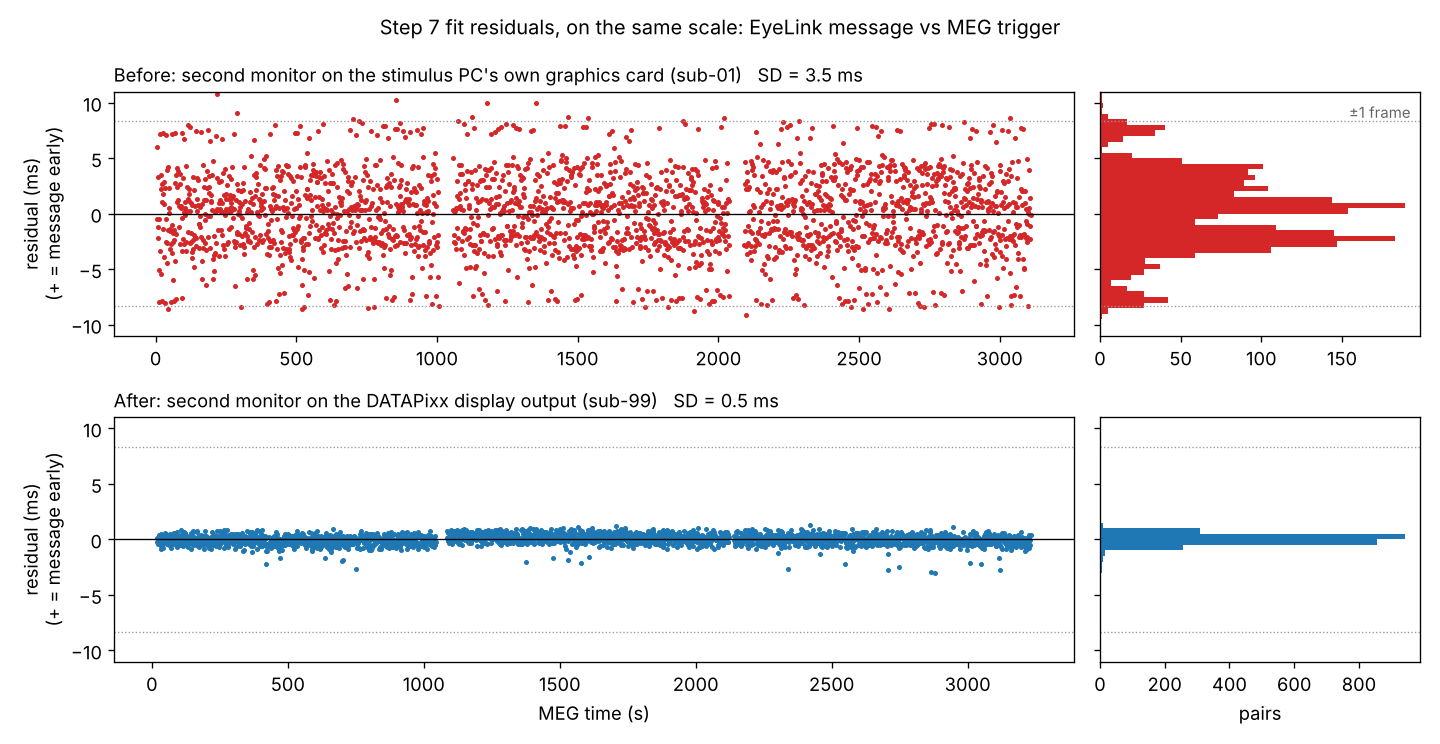

* **Before** (top, sub-01): the EyeLink messages are spread over about ±1 frame (the dotted
  lines, ±8.3 ms) around their MEG triggers. Residual SD 3.5 ms, largest 10.8 ms.
* **After** (bottom, sub-99, a test run with an artificial eye and no participant): the
  residuals form a thin band at 0. Residual SD 0.47 ms, largest 3.0 ms. The EyeLink
  message for the first tone after a pause is no longer different from the others
  (mean 0.05 ms, versus +2.6 ms before), and all event types average within ±0.2 ms.

**This is what good message timing looks like.** If Step 7 for your recording looks like
the bottom plot, your EyeLink messages are going out on the screen refresh. If it looks
like the top plot, they are not.

The figure was made with `code/make_05_before_after_figures.py` in the pygers-meg repo.

## 6.4 The EyeLink's analog output delay

This goes with **Step 14**. The lag Step 14 reports between the synced gaze (`ET_xpos`) and
the MEG's analog Eye X channel is mostly the EyeLink's own delay in making the analog
signal. SR Research (October 2026) told us how big that delay is and what sets it.

**The EDF file is in real time.** Each sample in the `.edf` is placed at the time the eye
was actually in that position. The **File Sample Filter** smooths the samples but doesn't
move them in time. So the eye data synced by this notebook, and the shared events used
to sync them, line up with the real gaze position and pupil size.

**The analog output is delayed.** The EyeLink makes the analog voltages from its digital
samples, and that takes a short time. The delay depends on the **Link/Analog Filter**
setting: each step up adds one sample of delay (2 ms at 500 Hz) and cuts the noise in the
analog signal by a factor of 2 to 3. At 500 Hz:

| Link/Analog Filter | Analog delay at 500 Hz | Analog noise |
|---|---|---|
| Off | 3 ms | Highest |
| Standard (the EyeLink's default) | 5 ms | 2-3 times lower than Off |
| Extra | 7 ms | 2-3 times lower again |

The analog signal is always a little noisier than the samples in the `.edf`, because of
the conversion to a voltage.

**The sample dataset** was recorded with **Extra** for both the File and the Link/Analog
filter, so Step 14 should find an analog lag of about **7 ms** for gaze, as long as the
EyeLink messages are on time. The sample recording, made before the monitor fix,
measured about 5.1 ms: the 2 ms difference is the shift explained in **What we found in
the MEG lab**.

**Which setting to use.** **Standard for both filters is a good compromise**:

* **Link/Analog: Standard.** 5 ms of delay, with much less noise than Off. Use Off only
  if you need the analog signal as fast as possible (for example, for real-time
  gaze-contingent use of the analog output) and can live with the extra noise. Extra
  adds another 2 ms for a smoother signal.
* **File: Standard.** The file filter doesn't affect timing, so this choice is only
  about how much the recorded samples are smoothed. Using the same level as the analog
  output means both signals are filtered the same way, so they look alike in Step 14.

The filters are set on the EyeLink Host PC, on the Set Options screen ("File Sample
Filter" and "Link/Analog Filter"). Whatever you choose, keep it the same for every
participant in a study, and note it with your data, because it changes the analog lag.

## 6.5 One sync event vs. shared events

A simpler way to sync, used by many labs, is a **single sync event**: one message to the
eye tracker and one trigger to the MEG at the start of the run. The time difference
between them gives the offset, and that's it:

$$t_{MEG} = \text{offset}_{1} + t_{eye} \qquad \text{(the slope is assumed to be exactly 1)}$$

That assumes the two clocks tick at exactly the same rate. They don't, quite: the
**clock drift** found in Step 7 makes the two clocks slowly pull apart, so a single-event
sync is right at the start of the run and gets steadily worse.

This section **pretends** only one sync event was recorded, using the first matched pair
of the run (from Step 6) as that event. Then it checks the one-event sync against **every other pair**. Those pairs were recorded on
both clocks, so they show the true error at each point in the run.

Nothing here changes the BIDS files or the synced FIF; the results only go in the sync
report, for reference.

In [ ]:
# --- The single sync event: the first matched pair of the run ---
pairs_by_time = pair_table.sort_values("t_meg").reset_index(drop=True)
sync_event = pairs_by_time.iloc[0]

# One-event sync: offset only, slope fixed at 1
offset_one = sync_event["t_meg"] - sync_event["t_eye"]

# MEG sampling rate (from the MEG file's header, without loading the data)
sfreq_meg_cmp = mne.io.read_info(meg_fif)["sfreq"]
meg_sample_ms = 1000.0 / sfreq_meg_cmp

# For every pair: where each method says the eye message happened on the MEG clock,
# minus where the MEG trigger really was. That's each method's error, in ms.
t_eye_all = pairs_by_time["t_eye"].to_numpy()
t_meg_all = pairs_by_time["t_meg"].to_numpy()
error_one_ms = (t_meg_all - (offset_one + t_eye_all)) * 1000        # one sync event
error_shared_ms = (t_meg_all - (offset + slope * t_eye_all)) * 1000  # shared events (= Step 7 residuals)

# Mean error over the last minute of pairs (one pair alone is noisy: EyeLink rounds to whole ms)
last_minute = t_meg_all >= t_meg_all[-1] - 60
end_one_ms = error_one_ms[last_minute].mean()
end_shared_ms = error_shared_ms[last_minute].mean()

# The drift seen by the one-event method is a straight line: (slope - 1) x time since the sync event.
drift_ms_per_min = (slope - 1.0) * 60 * 1000   # how many ms the clocks pull apart each minute

# How long after the sync event until the one-event error passes 1 MEG sample, 1 ms and 5 ms
def minutes_until(limit_ms):
    if slope == 1.0:
        return np.inf
    return limit_ms / abs(drift_ms_per_min)

comparison = pd.DataFrame({
    "": ["StartTime (s)", "Slope", "Largest error over the run (ms)", "Mean error, last minute of the run (ms)"],
    "One sync event": [round(offset_one, 6), 1.0,
                       round(np.abs(error_one_ms).max(), 2), round(end_one_ms, 2)],
    "Shared events": [round(offset, 6), round(slope, 9),
                      round(np.abs(error_shared_ms).max(), 2), round(end_shared_ms, 2)],
})
print(f"Sync event used: '{sync_event['eye_message']}' at {sync_event['t_meg']:.3f} s (MEG time)")
print(f"The two StartTime values differ by {(offset_one - offset) * 1000:+.2f} ms.\n")
display(comparison.set_index(""))

print(f"\nClock drift: {drift_ppm:+.1f} ppm, so the clocks pull apart by {abs(drift_ms_per_min):.2f} ms per minute.")
print("After a single sync event, the error passes:")
for label, limit in [(f"1 MEG sample ({meg_sample_ms:.2f} ms)", meg_sample_ms), ("1 ms", 1.0), ("5 ms", 5.0)]:
    print(f"   {label:24s} after {minutes_until(limit):6.1f} min")
print(f"This run lasted {(t_meg_all[-1] - t_meg_all[0]) / 60:.1f} min between the first and last pair.")

### 6.5.1 Plot: how the error grows over the run

Each dot is one message/trigger pair. **Shared events** (the method used in this
notebook) stay flat around 0: the scatter is EyeLink rounding message times to whole
milliseconds. **One sync event** starts near 0 at the sync event and then slopes away
steadily: that slope *is* the clock drift. The shaded band is ±1 MEG sample.

The one-event error is 0 at the sync event by definition. But that single pair has its
own rounding error (up to about 0.5 ms), which shifts the whole one-event line; shared
events average that out over all the pairs.

In [ ]:
fig4, ax4 = plt.subplots(figsize=(12, 4))
t_min = t_meg_all / 60   # MEG time in minutes
ax4.axhspan(-meg_sample_ms, meg_sample_ms, color="0.9", label=f"±1 MEG sample ({meg_sample_ms:.2f} ms)")
ax4.axhline(0, color="k", linewidth=0.8)
ax4.plot(t_min, error_shared_ms, ".", markersize=4, label="Shared events (offset + drift)")
ax4.plot(t_min, error_one_ms, ".", markersize=4, label="One sync event (offset only)")
ax4.plot(t_min[0], error_one_ms[0], "o", markersize=10, markerfacecolor="none",
         markeredgecolor="k", label="The sync event")
ax4.set_xlabel("MEG time (min)")
ax4.set_ylabel("error (ms)\n(true MEG time - predicted)")
ax4.set_title(f"Clock drift {drift_ppm:+.1f} ppm: one-event error is {end_one_ms:+.1f} ms in the last minute")
ax4.legend(loc="best", fontsize=9)
fig4.tight_layout()
plt.show()
fig4.savefig(out_dir / f"{eye_base}_desc-sync_oneevent.png", dpi=120)

In [ ]:
# Save the comparison in the sync report (it doesn't change any BIDS files)
report["OneEventComparison"] = {
    "Description": "For learning only: sync from a single message/trigger pair (offset only, slope 1), "
                   "checked against all matched pairs. Not used for StartTime or the synced FIF.",
    "SyncEventMessage": str(sync_event["eye_message"]),
    "SyncEventMEGTimeS": float(sync_event["t_meg"]),
    "StartTimeOneEventS": float(offset_one),
    "StartTimeDifferenceMs": float((offset_one - offset) * 1000),
    "DriftMsPerMinute": float(drift_ms_per_min),
    "MaxAbsErrorOneEventMs": float(np.abs(error_one_ms).max()),
    "MeanErrorLastMinuteOneEventMs": float(end_one_ms),
    "MaxAbsErrorSharedEventsMs": float(np.abs(error_shared_ms).max()),
}
out_report.write_text(json.dumps(report, indent=4))
print("Added to the sync report:", out_report.name)

## 6.6 Preview: finding trials with blinks

This goes with **Step 13**. It's a preview of something you'll do during preprocessing:
using the eye-tracking channels in the synced FIF to find trials you may want to exclude.
It doesn't change any files.

**What counts as a trial.** In the oddball task, each trial runs: fixation (1.5 s) → cue
arrow (0.5 s) → tones (several standards, then the deviant) → response window (1 s) →
error feedback (errors only) → **BLINK** (0.5 s). Participants are asked to blink only when
"BLINK" is on the screen and to hold their gaze on the cross the rest of the time. So a
blink anywhere *before* the BLINK cue is a blink they weren't supposed to make, and it may
spoil that trial.

**Choosing the window.** Four settings at the top of the cell define each trial: the MEG
event it starts from (`TRIAL_START_TYPE`), the event it ends at (`TRIAL_END_TYPE`), and how
many seconds to move each one (`START_SHIFT_S`, `END_SHIFT_S`; negative = earlier,
positive = later). The MEG trial types in the sample dataset are:

| Trial type | What it is |
|---|---|
| `"left cue"`, `"right cue"` | The cue arrow (0.5 s). The fixation cross appears 1.5 s before it. |
| `"standard"` | A standard tone (0.4 s) |
| `"deviant"` | The deviant tone (0.4 s), the last tone of the trial. The response window starts when it ends. |
| `"error feedback"` | Red feedback text, on error trials only |
| `"blink"` | The BLINK cue (0.5 s), at the end of every trial |

The cell also prints the trial types in your own `_events.tsv`. Some useful windows:

| Window | `TRIAL_START_TYPE` | `START_SHIFT_S` | `TRIAL_END_TYPE` | `END_SHIFT_S` |
|---|---|---|---|---|
| Fixation onset to the BLINK cue (all the time gaze should be held) | `["left cue", "right cue"]` | `-1.5` | `"blink"` | `0` |
| Fixation onset to the start of the response window | `["left cue", "right cue"]` | `-1.5` | `"deviant"` | `0.4` |
| First standard tone to the BLINK cue (the tones and the response) | `"standard"` | `0` | `"blink"` | `0` |
| First standard tone to the end of the deviant (the tones only) | `"standard"` | `0` | `"deviant"` | `0.4` |

How the shifts work out:

* **Fixation onset = cue − 1.5 s.** The fixation has no MEG trigger (only an EyeLink
  message), but the script shows the fixation cross, waits 1.5 s, and shows the cue on the
  next screen refresh.
* **Response window onset = deviant + 0.4 s.** The response window has no MEG trigger
  either, but it starts when the 0.4 s deviant tone ends. (Button presses are scored from
  150 ms after the deviant's onset, so this is the start of the 1 s fixation-only phase, not
  of the period when presses count.)
* Both can be up to one frame (8 ms) later than that, because the next stimulus waits for
  the next screen refresh. That doesn't matter for finding blinks.

**Two rules.** Each `TRIAL_END_TYPE` event ends one trial, so pick an end event that
happens **once in every trial** (the cues, the deviant or the BLINK cue; not the standard
tones, and not the error feedback, which only some trials have). The trial then starts from
the **first** `TRIAL_START_TYPE` event since the previous trial ended, so with `"standard"`
it starts at the first standard tone.

**How it works.**

1. It opens the synced FIF saved in Step 13, the same file you'll use for preprocessing.
2. It reads the trial start and end times from the MEG `_events.tsv`.
3. Step 13 marked every blink EyeLink detected with an `ET_blink` annotation. A trial "has
   a blink" if one of those blinks **starts** during the trial.

   **Blinks that start before the trial.** Participants blink when the BLINK screen of the
   *previous* trial appears. That screen lasts only 0.5 s and the next fixation starts right
   after it, so many of those blinks are still going on when the next trial starts. In the
   sample recording, nearly every trial begins with one, about 0.3 s after it started. These
   blinks are what the task asks for, so by default they aren't counted
   (`COUNT_BLINKS_STARTING_BEFORE = False`). Set it to `True` to count them too, for example
   if the eyes must be open from the very start of fixation; the time of such a blink is
   then **negative** in the `first_blink_after_start_s` column (it started before the trial).
4. It prints how many trials have 1, 2, 3 (or more) blinks, and lists the trials with
   blinks.
5. It plots `ET_xpos`, `ET_ypos` and `ET_pupil` for a few trials with 1 blink, a few with
   2 and a few with 3, with each blink shaded, so you can see what they look like
   (`BLINK_COUNTS` and `TRIALS_PER_GROUP` set which and how many).

**What to look for in the plots.** During a blink the eye tracker loses the pupil, so it
has no gaze or pupil data. Step 11 filled those gaps with a straight line (unless
`RESTORE_NAN = True`), so a blink looks like a short straight segment, usually with a
sharp dip or jump on either side as the eyelid closes and opens. The pupil channel shows
blinks most clearly.

In [ ]:
# --- Settings for this cell (you can change these) ---
# The window of each trial: the MEG event it starts from and the event it ends at, each
# moved by a number of seconds (negative = earlier, positive = later). The MEG trial types
# in the sample dataset (the cell prints the ones in your own _events.tsv):
#   "left cue", "right cue"  the cue arrow (0.5 s); the fixation starts 1.5 s before it
#   "standard"               a standard tone (0.4 s)
#   "deviant"                the deviant tone (0.4 s); the response window starts when it ends
#   "error feedback"         red feedback text (error trials only)
#   "blink"                  the BLINK cue (0.5 s), at the end of every trial
# The end type must happen once in every trial (the cues, "deviant" or "blink").
TRIAL_START_TYPE = ["left cue", "right cue"]   # one trial type in quotes, or a list of them
START_SHIFT_S = -0.5   # -1.5 = fixation onset (the fixation starts 1.5 s before the cue)
TRIAL_END_TYPE = "deviant"
END_SHIFT_S = 0.4      # 0.4 = the start of the response window (the deviant lasts 0.4 s)


BLINK_COUNTS = [1, 2, 3]   # plot trials with exactly this many blinks (one group for each)
TRIALS_PER_GROUP = 3       # how many trials of each group to plot
TRIALS_PER_ROW = 3         # trials side by side; more trials go on more rows of plots


# False = count only blinks that START during the trial.
# True  = also count blinks that started before the trial and were still going on when it
#         started (usually the blink cued by the previous trial's BLINK screen, which runs
#         into the next fixation). Their time from the trial start is then negative.
COUNT_BLINKS_STARTING_BEFORE = False

# --- 1) Open the synced FIF from Step 13 ---
# preload=False reads only the file's header now; the data are read later, one trial at a time.
# MNE finds the other split files (split-02, ...) by itself.
raw_synced = mne.io.read_raw_fif(saved[0], preload=False, verbose="error")
sfreq_synced = raw_synced.info["sfreq"]

# --- 2) Trial start and end times (seconds from the first MEG sample) ---
# They come from the MEG _events.tsv read in Step 5 (columns "trial_type" and "onset").
print("MEG trial types in this recording (how many of each):",
      meg_events_all["trial_type"].value_counts().to_dict(), "\n")

# Allow one name or a list of names for the start (e.g. both cue directions)
start_types = [TRIAL_START_TYPE] if isinstance(TRIAL_START_TYPE, str) else list(TRIAL_START_TYPE)
unknown = [t for t in start_types + [TRIAL_END_TYPE] if t not in set(meg_events_all["trial_type"])]
if unknown:
    raise ValueError(f"Not a trial type in the MEG _events.tsv: {unknown}. Pick from the list above "
                     "(names must match exactly, including capitals and spaces).")

start_times = np.sort(meg_events_all.loc[meg_events_all["trial_type"].isin(start_types), "onset"].to_numpy(float))
end_times = np.sort(meg_events_all.loc[meg_events_all["trial_type"] == TRIAL_END_TYPE, "onset"].to_numpy(float))

# Every end event ends one trial (moved by END_SHIFT_S). The trial starts from the FIRST start
# event after the previous end event (with the cues there is only one per trial; with
# "standard" this is the first standard tone of the trial), moved by START_SHIFT_S.
trials = []
previous_end = -np.inf
for end in end_times:
    starts_in_trial = start_times[(start_times > previous_end) & (start_times < end)]
    if len(starts_in_trial) > 0:
        trials.append((starts_in_trial[0] + START_SHIFT_S, end + END_SHIFT_S))
    previous_end = end
trials = pd.DataFrame(trials, columns=["start_s", "end_s"])
trials.index = trials.index + 1          # number the trials from 1, in the order they appear in the MEG run
                                         # (in the sample dataset the training trials weren't recorded by the MEG, so trial 1 is
                                         # the first main trial)
trials.index.name = "trial"

# --- 3) Blinks: the ET_blink annotations from Step 13 ---
# Annotation onsets are counted from the recording's measurement date, which is
# raw.first_time earlier than the first sample, so subtract it to get MEG time.
annot = raw_synced.annotations
annot_shift = raw_synced.first_time if annot.orig_time is not None else 0.0
is_blink = annot.description == BLINK_ANNOT
blink_start = annot.onset[is_blink] - annot_shift
blink_end = blink_start + annot.duration[is_blink]

# Which blinks count for each trial:
#   COUNT_BLINKS_STARTING_BEFORE = False: the blink starts at or after the trial start, and
#                                         before the trial ends.
#   COUNT_BLINKS_STARTING_BEFORE = True:  the blink overlaps the trial at all: it starts before
#                                         the trial ends AND ends after the trial starts.
blinks_per_trial, first_blink_s = [], []
for start, end in zip(trials["start_s"], trials["end_s"]):
    if COUNT_BLINKS_STARTING_BEFORE:
        overlaps = (blink_start < end) & (blink_end > start)
    else:
        overlaps = (blink_start >= start) & (blink_start < end)
    blinks_per_trial.append(int(overlaps.sum()))
    first_blink_s.append(round(blink_start[overlaps].min() - start, 2) if overlaps.any() else np.nan)
trials["blinks"] = blinks_per_trial
trials["first_blink_after_start_s"] = first_blink_s   # time of the first blink, from the trial start
                                                      # (negative = it started before the trial)
trials["duration_s"] = (trials["end_s"] - trials["start_s"]).round(2)

with_blinks = trials[trials["blinks"] > 0]
def describe(types, shift):
    # e.g. "1.5 s before 'left cue / right cue'", or just "'blink'" when there is no shift
    name = "'" + " / ".join(types) + "'"
    if shift == 0:
        return name
    return f"{abs(shift):g} s {'before' if shift < 0 else 'after'} {name}"


print(f"{len(trials)} trials (from {describe(start_types, START_SHIFT_S)} "
      f"to {describe([TRIAL_END_TYPE], END_SHIFT_S)}).")
print("Blinks that started before the trial are " + ("counted." if COUNT_BLINKS_STARTING_BEFORE else "not counted."))
print(f"{len(with_blinks)} of them have at least one blink "
      f"({len(with_blinks) / max(len(trials), 1) * 100:.0f} %):")
# How many trials have 0, 1, 2, 3 or more blinks
for n in range(0, 4):
    n_trials = int((trials["blinks"] == n).sum())
    print(f"   {n} blink{'s' if n != 1 else ''}: {n_trials:4d} trials")
print(f"   4 or more: {int((trials['blinks'] >= 4).sum()):4d} trials\n")
display(with_blinks.round(3))

# --- 4) Plot gaze and pupil for a few of those trials ---
channels_to_plot = [f"{ET_PREFIX}xpos", f"{ET_PREFIX}ypos", f"{ET_PREFIX}pupil"]
y_labels = ["gaze x (pixels)", "gaze y (pixels)", "pupil (a.u.)"]
# The other MEG events, to mark the cue, the tones and the deviant in each trial
marks = {"left cue": ("C2", "-"), "right cue": ("C2", "-"), "standard": ("0.6", ":"), "deviant": ("C3", "--")}



def plot_trials(to_plot):
    # Plot gaze x, gaze y and pupil for each trial in to_plot (a table of trials), with
    # TRIALS_PER_ROW trials side by side in each figure, so every plot keeps the same size.
    for row_start in range(0, len(to_plot), TRIALS_PER_ROW):
        chunk = to_plot.iloc[row_start:row_start + TRIALS_PER_ROW]
        fig7, axes7 = plt.subplots(len(channels_to_plot), TRIALS_PER_ROW,
                                   figsize=(5 * TRIALS_PER_ROW, 6), squeeze=False)
        for col, (trial_number, trial) in enumerate(chunk.iterrows()):
            # Read only this trial's samples (plus 0.5 s on each side) for the three channels
            first = max(int((trial["start_s"] - 0.5) * sfreq_synced), 0)
            last = min(int((trial["end_s"] + 0.5) * sfreq_synced), raw_synced.n_times)
            data = raw_synced.get_data(picks=channels_to_plot, start=first, stop=last)
            t = np.arange(first, last) / sfreq_synced - trial["start_s"]   # time from the trial start
            for row, (name, label) in enumerate(zip(channels_to_plot, y_labels)):
                ax = axes7[row, col]
                ax.plot(t, data[row], linewidth=0.8, color="C0")
                # Shade each blink in this window
                for b0, b1 in zip(blink_start, blink_end):
                    if b1 > trial["start_s"] - 0.5 and b0 < trial["end_s"] + 0.5:
                        ax.axvspan(b0 - trial["start_s"], b1 - trial["start_s"], color="C1", alpha=0.3)
                # Mark the trial start and end, and the cue and tones in between
                ax.axvline(0, color="k", linewidth=1)
                ax.axvline(trial["end_s"] - trial["start_s"], color="k", linewidth=1)
                for kind, (color, style) in marks.items():
                    times = meg_events_all.loc[meg_events_all["trial_type"] == kind, "onset"].to_numpy(float)
                    for tone in times[(times > trial["start_s"]) & (times < trial["end_s"])]:
                        ax.axvline(tone - trial["start_s"], color=color, linestyle=style, linewidth=0.8)
                if col == 0:
                    ax.set_ylabel(label)
                if row == 0:
                    ax.set_title(f"Trial {trial_number}: {int(trial['blinks'])} blink(s)")
                if row < len(channels_to_plot) - 1:
                    ax.tick_params(labelbottom=False)   # time labels only on the bottom row
            axes7[-1, col].set_xlabel("time from trial start (s)")
        for col in range(len(chunk), TRIALS_PER_ROW):   # hide empty spots in the last row
            for row in range(len(channels_to_plot)):
                axes7[row, col].set_visible(False)
        fig7.tight_layout()
        plt.show()


print("In the plots: orange = blinks, black lines = trial start and end, green = cue, "
      "dotted = standard tones, red dashed = deviant.")
for n in BLINK_COUNTS:
    group = trials[trials["blinks"] == n]
    label = f"Trials with {n} blink{'s' if n != 1 else ''}"
    if len(group) == 0:
        print(f"\n{label}: none.")
        continue
    print(f"\n{label}: {len(group)} in total, showing the first {min(TRIALS_PER_GROUP, len(group))}.")
    plot_trials(group.head(TRIALS_PER_GROUP))